In [ ]:
import os
from pathlib import Path

import warnings
import seaborn as sns
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import json
from sklearn.model_selection import LeaveOneGroupOut, ParameterGrid, KFold, GroupKFold, StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score, precision_score, confusion_matrix
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    median_absolute_error,
    explained_variance_score
)
import catboost as cb
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVR, SVC
from catboost import CatBoostClassifier, CatBoostRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, ElasticNet


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer

import shap
import numba
from sktime.transformations.panel.rocket import Rocket
from sklearn.base import clone
from collections import Counter


In [2]:
import logging
import time

# Logger per timing
timing_logger = logging.getLogger("timing")
timing_logger.setLevel(logging.INFO)
timing_handler = logging.FileHandler("timing.log", mode='w')
timing_formatter = logging.Formatter("%(asctime)s - %(message)s")
timing_handler.setFormatter(timing_formatter)
timing_logger.addHandler(timing_handler)

In [3]:
# Suppress warnings
warnings.filterwarnings('ignore')

In [4]:
# Set random seed for reproducibility
seed = 69
#torch.manual_seed(seed)
np.random.seed(seed)

In [5]:
# Define directories
ROOT = Path('.').resolve()
DATA_DIR = ROOT / 'data'
OUTPUTS_DIR = ROOT / 'outputs' / 'run_v7'
TABLES_DIR = OUTPUTS_DIR / 'tables'
FIGURES_DIR = OUTPUTS_DIR / 'figures'

for d in [TABLES_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

In [6]:
df = pd.read_csv(DATA_DIR / 'maison-llf-features.csv', sep=",")  ### maison-llf-features_TEST.CSV

ana = pd.read_csv(DATA_DIR / 'maison-llf-demographics.csv', sep=",")  ### maison-llf-demographics_TEST

In [7]:
# Convert timestamp to datetime for sorting and rolling features later
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [8]:
print("=== Files loaded ===")
print(f"  features.csv       : {df.shape[0]} rows x {df.shape[1]} cols")
print(f"  demographics.csv   : {ana.shape[0]} rows x {ana.shape[1]} cols")
print()

df.head(2)

=== Files loaded ===
  features.csv       : 1008 rows x 84 cols
  demographics.csv   : 18 rows x 8 cols



,participant,timestamp,clinical-timestamp,sis-01,sis-02,sis-03,sis-04,sis-05,sis-06,sis,...,sleep-duration-to-wakeup,sleep-wakeup-count,sleep-heartrate-mean,sleep-heartrate-min,sleep-heartrate-max,step-count,step-ratio,step-mean,step-max,step-max-timestamp
0,1,2022-03-31,2022-04-13,5,5,4,4,5,2,25,...,0.0,3,59,54,74,415,0.5000,34.5833,106,13
1,1,2022-04-01,2022-04-13,5,5,4,4,5,2,25,...,0.0,4,61,56,82,447,0.2917,63.8571,185,8


In [9]:
ana_col = list(ana.columns)

ana_encoded = ana[["participant", "age", "sex", "education", "work", "fracture-type", "ethnicity"]].copy()

# male=1, female=0
ana_encoded["sex_male"] = ana_encoded["sex"].map({"male": 1, "female": 0})

# Education label encoding with doctorate as highest level
education_order = {
    "secondary education": 0,
    "undergraduate degree": 1,
    "graduate degree": 2,
    "doctorate degree": 3
}
ana_encoded["education_label"] = ana_encoded["education"].map(education_order)

# retired=0, employed part-time=1
ana_encoded["work_part_time"] = ana_encoded["work"].map({"retired": 0, "employed part-time": 1})

In [10]:
fracture_dummies = pd.get_dummies(
    ana_encoded["fracture-type"],
    prefix="fracture",
    dtype=int
)

In [11]:
ethnicity_dummies = pd.get_dummies(
    ana_encoded["ethnicity"],
    prefix="ethnicity",
    dtype=int
)

In [12]:
num_ana = pd.concat(
    [
        ana_encoded[["participant", "age", "sex_male", "education_label", "work_part_time"]],
        fracture_dummies,
        ethnicity_dummies,
    ],
    axis=1,
)

In [13]:
# Merge demographics into the feature table
data = df.merge(num_ana, how='right', on='participant')

In [14]:
assert data.shape[0] == df.shape[0], f"Row count changed after merge: {df.shape[0]} -> {data.shape[0]}"

In [15]:
missing_after_merge = data.isna().sum().sum()

In [16]:
assert missing_after_merge == 0, f"Missing demographics after merge ({missing_after_merge} NaNs) — participant ID mismatch?"

In [17]:
print("=== Merge result ===")
print(f"  df_raw shape    : {df.shape}")
print(f"  df_merged shape : {data.shape}")

=== Merge result ===
  df_raw shape    : (1008, 84)
  df_merged shape : (1008, 95)


In [18]:
print("=" * 60)
print("BASIC INPUT DATA CHECKS")
print("=" * 60)

# 1. Shape
print("\n--- Shape ---")
n_participants = df['participant'].nunique()
rows_per_part  = df.shape[0] // n_participants
print(f"  features  : {df.shape[0]} rows x {df.shape[1]} cols")
print(f"              {n_participants} participants x {rows_per_part} days per participant")
print(f"  ana      : {num_ana.shape[0]} rows x {num_ana.shape[1]} cols")

BASIC INPUT DATA CHECKS

--- Shape ---
  features  : 1008 rows x 84 cols
              18 participants x 56 days per participant
  ana      : 18 rows x 12 cols


In [19]:
# 2. Missing values
print("\n--- Missingness ---")
feat_null_total = df.isna().sum().sum()
demo_null_total = num_ana.isna().sum().sum()
print(f"  features.csv  : {feat_null_total} total NaN values")
print(f"  demographics.csv  : {demo_null_total} total NaN values")

feat_null_cols = df.columns[df.isna().any()].tolist()
feat_null_cols


--- Missingness ---
  features.csv  : 0 total NaN values
  demographics.csv  : 0 total NaN values


[]

In [20]:
if feat_null_cols:
    print(f"  [WARN] Columns with nulls in features: {feat_null_cols}")
    print(df[feat_null_cols].isna().sum().to_string())
else:
    print("  [OK] No missing values in features")

demo_null_cols = num_ana.columns[num_ana.isna().any()].tolist()
if demo_null_cols:
    print(f"  [WARN] Columns with nulls in demographics: {demo_null_cols}")
else:
    print("  [OK] No missing values in demographics")

  [OK] No missing values in features
  [OK] No missing values in demographics


In [21]:
# 3. Duplicates
print("\n--- Duplicate Keys ---")
dup_full = df.duplicated().sum()   ### tiene la prima occorrenza come originale (False); le copie successive sono True.
dup_key  = df.duplicated(subset=['participant', 'timestamp']).sum()
dup_demo = num_ana.duplicated(subset=['participant']).sum()
print(f"  features full-row duplicates           : {dup_full}")
print(f"  features (participant, timestamp) dupes: {dup_key}")
print(f"  demographics participant duplicates    : {dup_demo}")

assert dup_key  == 0, f"Duplicate (participant, timestamp) keys: {dup_key}"
assert dup_demo == 0, f"Duplicate participant rows in demographics: {dup_demo}"


--- Duplicate Keys ---
  features full-row duplicates           : 0
  features (participant, timestamp) dupes: 0
  demographics participant duplicates    : 0


In [22]:
# 4. Participant balance
print("\n--- Participant Balance ---")
rows_by_part = data.groupby('participant').size()
print(f"  Rows per participant: min={rows_by_part.min()}, max={rows_by_part.max()}, "
      f"all equal={rows_by_part.nunique()==1}")  ### nunique() è un metodo di pandas, conta quanti valori distinti ci sono
assert rows_by_part.nunique() == 1, f"Participants have unequal row counts: {rows_by_part.to_dict()}"



--- Participant Balance ---
  Rows per participant: min=56, max=56, all equal=True


In [23]:
# 5. Timestamp ordering
print("\n--- Timestamp Coverage ---")
print(f"  Global date range: {data['timestamp'].min().date()} to {data['timestamp'].max().date()}")
dup_ts = data.groupby('participant')['timestamp'].apply(lambda x: x.duplicated().sum())  ### somma i timestamp duplicati per ogni partecipante
assert dup_ts.sum() == 0, f"Duplicate timestamps within participants: {dup_ts[dup_ts>0]}"


--- Timestamp Coverage ---
  Global date range: 2022-03-31 to 2025-10-29


In [24]:
# 6. Target ranges
print("\n--- Target Distributions ---")
for t in ['sis', 'ohs', 'oks']:
    s = data[t]
    print(f"  {t}: min={s.min():4} max={s.max():4} mean={s.mean():.2f} "
          f"std={s.std():.2f} nulls={s.isna().sum()}")


--- Target Distributions ---
  sis: min=  15 max=  30 mean=23.86 std=3.84 nulls=0
  ohs: min=  13 max=  47 mean=28.17 std=8.06 nulls=0
  oks: min=  15 max=  48 mean=30.22 std=9.69 nulls=0


In [25]:
# Set column names used throughout the notebook

PARTICIPANT_COL = 'participant'
DATE_COL        = 'timestamp'
CLINICAL_TS_COL = 'clinical-timestamp'
TARGET_SIS      = 'sis'
TARGET_OHS      = 'ohs'
TARGET_OKS      = 'oks'    # Oxford Knee Score total
WINDOWS         = [3, 7, 14]

In [26]:
# Questionnaire sub-items that directly sum to the targets
SIS_SUBITEMS = [f'sis-0{i}' for i in range(1, 7)]
SIS_SUBITEMS

['sis-01', 'sis-02', 'sis-03', 'sis-04', 'sis-05', 'sis-06']

In [27]:
OHS_SUBITEMS = [f'ohs-{str(i).zfill(2)}' for i in range(1, 13)]     # ohs-01..ohs-12
### zfill(2) riempie la stringa a sinistra con zeri finché non arriva a 2 caratteri.

In [28]:
OKS_SUBITEMS   = [f'oks-{str(i).zfill(2)}' for i in range(1, 13)]   # oks-01..oks-12
CLINICAL_TESTS = ['tug', 'chairstand']


In [29]:
# Columns always removed before modelling
COLS_DROP_ALWAYS = (
    SIS_SUBITEMS
    + OHS_SUBITEMS
    + OKS_SUBITEMS
    + CLINICAL_TESTS
    + [CLINICAL_TS_COL]
)

#COLS_DROP_ALWAYS

In [30]:
# Sensor columns grouped by modality
SENSOR_MODALITIES = {
    'acceleration': [c for c in df.columns if c.startswith('acceleration')],
    'heartrate'   : [c for c in df.columns if c.startswith('heartrate')],
    'motion'      : [c for c in df.columns if c.startswith('motion')],
    'position'    : [c for c in df.columns if c.startswith('position')],
    'sleep'       : [c for c in df.columns if c.startswith('sleep')],
    'step'        : [c for c in df.columns if c.startswith('step')],
}

#SENSOR_MODALITIES

In [31]:
SAFE_SENSOR_COLS = [c for cols in SENSOR_MODALITIES.values() for c in cols]

#risultato = []
#for cols in SENSOR_MODALITIES.values():   # ogni valore è una lista di colonne
#    for c in cols:                         # ogni colonna dentro quella lista
#        risultato.append(c)

#SAFE_SENSOR_COLS

In [32]:
# Demographic columns used later in the preprocessing pipeline
ANA_QUAL_COLS = ['sex', 'fracture-type', 'relationship', 'education', 'work', 'ethnicity']
ANA_QUAN_COLS = ['age']

print("=== Column constants set ===")
print(f"  COLS_DROP_ALWAYS: {len(COLS_DROP_ALWAYS)} columns")
print(f"  Safe sensor cols: {len(SAFE_SENSOR_COLS)} across {len(SENSOR_MODALITIES)} modalities")
for mod, cols in SENSOR_MODALITIES.items():
    print(f"    {mod:<14}: {len(cols)} features")
print(f"  ANA qualitative cols   : {ANA_QUAL_COLS}")
print(f"  ANA quantitative cols   : {ANA_QUAN_COLS}")

=== Column constants set ===
  COLS_DROP_ALWAYS: 33 columns
  Safe sensor cols: 46 across 6 modalities
    acceleration  : 16 features
    heartrate     : 6 features
    motion        : 5 features
    position      : 3 features
    sleep         : 11 features
    step          : 5 features
  ANA qualitative cols   : ['sex', 'fracture-type', 'relationship', 'education', 'work', 'ethnicity']
  ANA quantitative cols   : ['age']


In [33]:
# Drop leakage columns
cols_present_to_drop = [c for c in COLS_DROP_ALWAYS if c in data.columns]
cols_not_found       = [c for c in COLS_DROP_ALWAYS if c not in data.columns]
cols_not_found

[]

In [34]:
df_merged = data.copy()

In [35]:
data = df_merged.drop(columns=COLS_DROP_ALWAYS, errors='ignore').copy()

In [36]:
#print("=== Leakage Removal Report ===")
#print(f"Raw columns          : {df_raw.shape[1]}")
#print(f"Columns to drop      : {len(COLS_DROP_ALWAYS)} specified")
#print(f"  -> Found & dropped : {len(cols_present_to_drop)}")
#for c in cols_present_to_drop:
#    print(f"      DROPPED: {c}")
#if cols_not_found:
#    print(f"  -> Not found (OK)  : {cols_not_found}")
#print(f"Remaining columns    : {df.shape[1]}")
#print()

#forbidden_still_present = [c for c in COLS_DROP_ALWAYS if c in df.columns]
#assert len(forbidden_still_present) == 0, \
#    f"LEAKAGE NOT REMOVED: {forbidden_still_present}"

#for must_have in [PARTICIPANT_COL, DATE_COL, TARGET_SIS, TARGET_OHS, TARGET_OKS]:
#    assert must_have in df.columns, f"Required column missing: {must_have}"

#print("[OK] All forbidden columns removed")
#print(f"[OK] Retained: {PARTICIPANT_COL}, {DATE_COL}, {TARGET_SIS}, {TARGET_OHS}, {TARGET_OKS}")

In [37]:
print("Remaining columns:")
print(list(data.columns))

Remaining columns:
['participant', 'timestamp', 'sis', 'ohs', 'oks', 'acceleration-count', 'acceleration-mean', 'acceleration-std', 'acceleration-sum', 'acceleration-entropy', 'acceleration-kurtosis', 'acceleration-skew', 'acceleration-coefficient-of-variation', 'acceleration-minutes-with-data', 'acceleration-hours-with-data', 'acceleration-movement-events-00to06', 'acceleration-movement-events-06to12', 'acceleration-movement-events-12to18', 'acceleration-movement-events-18to24', 'acceleration-movement-events-24h', 'acceleration-intradaily-variability', 'heartrate-count', 'heartrate-min', 'heartrate-max', 'heartrate-mean', 'heartrate-std', 'heartrate-hours-with-data', 'motion-count', 'motion-ratio', 'motion-mean', 'motion-max', 'motion-max-timestamp', 'position-count', 'position-duration', 'position-distance-travelled', 'sleep-total', 'sleep-deep', 'sleep-light', 'sleep-rem', 'sleep-snoring', 'sleep-duration-to-sleep', 'sleep-duration-to-wakeup', 'sleep-wakeup-count', 'sleep-heartrate-

In [38]:
df_invest = data.copy()
df_invest[CLINICAL_TS_COL] = df_merged[CLINICAL_TS_COL]  ## rimosso prima


In [39]:
inconsistent_pids = []
for pid in sorted(df_invest[PARTICIPANT_COL].unique()):
    sub = df_invest[df_invest[PARTICIPANT_COL] == pid]
    grp = sub.groupby(CLINICAL_TS_COL)[[TARGET_SIS, TARGET_OHS, TARGET_OKS]].agg(
        lambda x: x.nunique()  ## nunique() ne conta i distinti
    )
    if (grp > 1).any(axis=1).any():  ## .any(axis=1) guarda ogni riga e restituisce True se in quella riga c’è almeno un True, poi any() guarda alla serie e restituisce True se in quella serie c’è almeno un True
        print(f"  [FLAG] Participant {pid}: unique SIS/OHS/OKS counts per clinical-timestamp block:")
        print(grp.to_string(index=True))
        detail = sub.groupby(CLINICAL_TS_COL)[[TARGET_SIS, TARGET_OHS, TARGET_OKS]].apply(
            lambda g: g[[TARGET_SIS, TARGET_OHS, TARGET_OKS]].drop_duplicates()
        )
        print("     Actual SIS/OHS/OKS values within each block:")
        print(detail.to_string())   #### mostra i valori originali
        print()
        inconsistent_pids.append(pid)

### dentro ogni blocco di clinical-timestamp ci devono essere valori tutti uguali per SIS, OHS e OKS

  [FLAG] Participant 10: unique SIS/OHS/OKS counts per clinical-timestamp block:
                    sis  ohs  oks
clinical-timestamp               
2024-11-06            2    2    2
2024-11-20            2    2    2
2024-12-04            1    1    1
2024-12-18            1    1    1
     Actual SIS/OHS/OKS values within each block:
                        sis  ohs  oks
clinical-timestamp                   
2024-11-06         504   19   19   26
                   517   21   13   27
2024-11-20         518   19   19   26
                   519   21   13   27
2024-12-04         532   20   18   25
2024-12-18         546   18   28   34

  [FLAG] Participant 11: unique SIS/OHS/OKS counts per clinical-timestamp block:
                    sis  ohs  oks
clinical-timestamp               
2024-11-12            1    1    1
2024-11-26            1    1    1
2024-12-10            1    1    2
2024-12-24            1    1    2
     Actual SIS/OHS/OKS values within each block:
                        s

In [40]:
print(f"Participants with inconsistencies: {inconsistent_pids}")

Participants with inconsistencies: [np.int64(10), np.int64(11), np.int64(12), np.int64(15)]


In [41]:
# Replace each clinical block with its median target value
df_resolve = data.copy()
df_resolve[CLINICAL_TS_COL] = df_merged[CLINICAL_TS_COL]

for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
    block_median = (
        df_resolve
        .groupby([PARTICIPANT_COL, CLINICAL_TS_COL])[target]
        .transform('median')  ## median, which keeps the majority value and avoids using information from other blocks.
    )  ## le parentesi servono solo a spezzare la riga, senza usare \
    df_resolve[target] = block_median.round().astype(int)

df_resolve = df_resolve.drop(columns=[CLINICAL_TS_COL])

In [42]:
# Check that each block now has only one target value
df_verify = df_resolve.copy()
df_verify[CLINICAL_TS_COL] = df_merged[CLINICAL_TS_COL]

print("=== Post-Resolution Verification ===")
all_clean = True
for pid in sorted(df_verify[PARTICIPANT_COL].unique()):
    sub = df_verify[df_verify[PARTICIPANT_COL] == pid]
    grp = sub.groupby(CLINICAL_TS_COL)[[TARGET_SIS, TARGET_OHS, TARGET_OKS]].nunique()
    if (grp > 1).any(axis=1).any():
        print(f"  [FAIL] P{pid}: still inconsistent after resolution!")
        print(grp)
        all_clean = False

if all_clean:
    print("  [OK] All {participant, clinical-timestamp} blocks have exactly 1 unique SIS/OHS/OKS value.")

=== Post-Resolution Verification ===
  [OK] All {participant, clinical-timestamp} blocks have exactly 1 unique SIS/OHS/OKS value.


In [43]:
print("Updated target stats after median-resolution:")
for t in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
    s = df_resolve[t]
    print(f"  {t}: min={s.min()} max={s.max()} mean={s.mean():.2f} std={s.std():.2f}")

df_model = df_resolve.copy()
print()
print(f"[OK] df_model shape: {df_model.shape} (rows, cols)")

Updated target stats after median-resolution:
  sis: min=15 max=30 mean=23.86 std=3.84
  ohs: min=13 max=47 mean=28.17 std=8.06
  oks: min=15 max=48 mean=30.22 std=9.69

[OK] df_model shape: (1008, 62) (rows, cols)


In [44]:
# Final check before modelling
FORBIDDEN_IN_MODEL = (
    SIS_SUBITEMS + OHS_SUBITEMS + OKS_SUBITEMS + CLINICAL_TESTS + [CLINICAL_TS_COL]
    # TARGET_OKS ('oks') is not included here because it is a prediction target
)

leaked = [c for c in FORBIDDEN_IN_MODEL if c in df_model.columns]
assert len(leaked) == 0, f"LEAKAGE GATE FAILED: {leaked}"
assert TARGET_SIS in df_model.columns, "TARGET_SIS missing from df_model"
assert TARGET_OHS in df_model.columns, "TARGET_OHS missing from df_model"
assert TARGET_OKS in df_model.columns, "TARGET_OKS missing from df_model"
missing_sensor = [c for c in SAFE_SENSOR_COLS if c not in df_model.columns]
assert len(missing_sensor) == 0, f"Sensor cols missing: {missing_sensor}"

In [45]:
FORBIDDEN_IN_MODEL == COLS_DROP_ALWAYS

True

In [46]:
print("=== Final Leakage Gate ===")
print(f"  Forbidden columns in df_model : {leaked} -> PASS")
print(f"  Targets present               : {TARGET_SIS}, {TARGET_OHS}, {TARGET_OKS} -> PASS")
print(f"  Sensor cols present           : {len(SAFE_SENSOR_COLS)} / {len(SAFE_SENSOR_COLS)} -> PASS")
print()
print("=== df_model Column Inventory ===")
print(f"  Total columns: {df_model.shape[1]}")
print(f"  Metadata     : {PARTICIPANT_COL}, {DATE_COL}")
print(f"  Targets      : {TARGET_SIS}, {TARGET_OHS}, {TARGET_OKS}")
print(f"  Sensor feats : {len(SAFE_SENSOR_COLS)} across {len(SENSOR_MODALITIES)} modalities")
for mod, cols in SENSOR_MODALITIES.items():
    print(f"    {mod:<14}: {len(cols)}")
print()
display(df_model.head(3))

=== Final Leakage Gate ===
  Forbidden columns in df_model : [] -> PASS
  Targets present               : sis, ohs, oks -> PASS
  Sensor cols present           : 46 / 46 -> PASS

=== df_model Column Inventory ===
  Total columns: 62
  Metadata     : participant, timestamp
  Targets      : sis, ohs, oks
  Sensor feats : 46 across 6 modalities
    acceleration  : 16
    heartrate     : 6
    motion        : 5
    position      : 3
    sleep         : 11
    step          : 5



,participant,timestamp,sis,ohs,oks,acceleration-count,acceleration-mean,acceleration-std,acceleration-sum,acceleration-entropy,...,sex_male,education_label,work_part_time,fracture_femur fracture,fracture_hip fracture,fracture_hip replacement,fracture_pelvis fracture,ethnicity_black,ethnicity_caucasian,ethnicity_south asian
0,1,2022-03-31,25,25,31,8499,9.8094,0.4333,83370.5096,3.6984,...,0,1,0,0,1,0,0,1,0,0
1,1,2022-04-01,25,25,31,5578,9.8284,0.4084,54822.8386,3.9855,...,0,1,0,0,1,0,0,1,0,0
2,1,2022-04-02,25,25,31,9036,9.8315,0.4115,88826.4654,3.9544,...,0,1,0,0,1,0,0,1,0,0


# Preprocessing pipeline

In [ ]:
def build_preprocessor(num_cols=None):
    """
    Build the preprocessing block for numeric and categorical features.

    This is created inside each LOPO fold so all preprocessing is fit on
    training participants only.
    """
    if num_cols is None:
        num_cols = SAFE_SENSOR_COLS + ANA_QUAN_COLS   # sensor-only

    numeric_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),  # SimpleImputer di scikit-learn riempie i valori mancanti (NaN) di una tabella con una statistica calcolata sulle colonne
        ('scale',  RobustScaler()),  # RobustScaler porta ogni colonna su una scala comune usando mediana e scarto interquartile
    ])

    cat_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OrdinalEncoder(  ## applica un OrdinalEncoder (ordine alfabetico)  ## TODO: non mi piace
            handle_unknown='use_encoded_value',   ## handle_unknown='use_encoded_value' dice cosa fare se in transform compare una categoria mai vista in fit. Invece di sollevare un errore, le scrive unknown_value=-1
            unknown_value=-1, 
        )),
    ])

    return ColumnTransformer(  ## applica trasformazioni alle colonne
        transformers=[
            ('num', numeric_pipe, num_cols),
            ('cat', cat_pipe, ANA_QUAL_COLS),
        ],
        remainder='drop',   # drop metadata and non-feature columns (butta le colonne non elencate, come participant e timestamp)
    )

def build_model_pipeline(model, num_cols=None):
    """
    Build a full pipeline: preprocessing + model.
    """
    steps = [('preprocess', build_preprocessor(num_cols=num_cols))]  ## steps è una lista
    steps.append(('model', model))
    return Pipeline(steps)

# Feature columns before rolling features are added
# 46 sensor + 1 age + 6 categorical demographics = 53 features
FEAT_COLS = SAFE_SENSOR_COLS + ANA_QUAN_COLS + ANA_QUAL_COLS

In [48]:
def _ols_slope(x):
    """
    Compute the slope against a simple time index.
    """
    n = len(x)
    if n < 2:
        return np.nan
    t   = np.arange(n, dtype=np.float64)
    t_c = t - t.mean()
    d   = np.dot(t_c, t_c)  ## somma dei quadrati dei numeri in t_c
    if d == 0.0:
        return np.nan
    return np.dot(t_c, x - x.mean()) / d   ## sarebbe la slope della regressione lineare tra t (time) e x (variabile)

In [49]:
def make_features(df, windows=None):
    """
    Add rolling-window features for each participant after sorting by time.
    """
    if windows is None:
        windows = WINDOWS

    # Sort by participant and time before computing rolling features
    df = df.sort_values([PARTICIPANT_COL, DATE_COL]).reset_index(drop=True)

    parts = []
    for _, grp in df.groupby(PARTICIPANT_COL, sort=False): # _ è l'id partecipante
        grp = grp.sort_values(DATE_COL).reset_index(drop=True)
        new_cols = {}
        for W in windows:
            for col in SAFE_SENSOR_COLS:
                s         = grp[col].astype(np.float64)
                roll_min1 = s.rolling(window=W, min_periods=1)  ### prepara una finestra mobile: per ogni giorno, la finestra prende quel giorno e i W - 1 precedenti. Con W = 7, il giorno 10 usa i giorni 4, 5, 6, 7, 8, 9 e 10.
                roll_min2 = s.rolling(window=W, min_periods=2)
                new_cols[f'{col}__roll{W}_mean']  = roll_min1.mean()  # se usassi solo min_periods=2, media, minimo e massimo del primo giorno diventerebbero NaN, perchè avrei 1 (dato) < 2 (min_periods)
                new_cols[f'{col}__roll{W}_std']   = roll_min2.std()
                new_cols[f'{col}__roll{W}_min']   = roll_min1.min()
                new_cols[f'{col}__roll{W}_max']   = roll_min1.max()
                new_cols[f'{col}__roll{W}_slope'] = roll_min2.apply(
                    _ols_slope, raw=True
                )
        parts.append(pd.concat([grp, pd.DataFrame(new_cols, index=grp.index)], axis=1))  ## in parts: un blocchetto per ogni partecipante
        ## grp.index è un indice nuovo, creato dentro il ciclo, non è l'id del partecipante
        ## le colonne di grp, compresa participant, (e le righe)restano com'erano, non essendoci una funzione agg che schiaccia la porzione di df (grp) su una riga (rendendo il partecipante unico/chiave)

    return pd.concat(parts, ignore_index=True)


In [50]:
# Rolling feature names
ROLLED_SENSOR_COLS = [
    f'{col}__roll{W}_{stat}'
    for col in SAFE_SENSOR_COLS
    for W    in WINDOWS
    for stat in ['mean', 'std', 'min', 'max', 'slope']
]

In [51]:
# Feature lists used later in the LOPO pipeline
ALL_NUM_COLS     = SAFE_SENSOR_COLS + ROLLED_SENSOR_COLS + ANA_QUAN_COLS
FEAT_COLS_ROLLED = ALL_NUM_COLS + ANA_QUAL_COLS

https://chatgpt.com/s/t_6adddf8f600081918e91b4f4f9285069   (GroupKFold)

In [52]:
# Compute quartiles for discretization
siss_q1, siss_q2, siss_q3 = np.percentile(df_model["sis"], [25, 50, 75])
ohss_q1, ohss_q2, ohss_q3 = np.percentile(df_model["ohs"], [25, 50, 75])
okss_q1, okss_q2, okss_q3 = np.percentile(df_model["oks"], [25, 50, 75])

# Define quartile-based bins and labels
quartile_labels = [0, 1, 2, 3]

# Apply discretization
df_model["SISS_Category_Q"] = pd.cut(df_model["sis"], bins=[df_model["sis"].min(), siss_q1, siss_q2, siss_q3, df_model["sis"].max()],
                               labels=quartile_labels, include_lowest=True).astype(int)
df_model["OHSS_Category_Q"] = pd.cut(df_model["ohs"], bins=[df_model["ohs"].min(), ohss_q1, ohss_q2, ohss_q3, df_model["ohs"].max()],
                               labels=quartile_labels, include_lowest=True).astype(int)

df_model["OKSS_Category_Q"] = pd.cut(df_model["oks"], bins=[df_model["oks"].min(), okss_q1, okss_q2, okss_q3, df_model["oks"].max()],
                               labels=quartile_labels, include_lowest=True).astype(int)

# Phase 4 — Modelling

In [53]:
# Hyperparameter grids used in the inner CV search

PARAM_GRID_RIDGE = {
    'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0],
}
PARAM_GRID_RF = {
    'model__n_estimators'    : [200],
    'model__max_depth'       : [5, 10, None],
    'model__min_samples_leaf': [2, 5],
}
PARAM_GRID_LGB = {
    'model__n_estimators' : [100, 300],
    'model__learning_rate': [0.05, 0.1],
    'model__num_leaves'   : [31, 63],
}
PARAM_GRID_ELASTICNET = {
    'model__alpha'   : [0.01, 0.1, 1.0, 10.0],
    'model__l1_ratio': [0.1, 0.5, 0.9],
}

print("=== Hyperparameter Grids ===")
for name, grid in [('Ridge',       PARAM_GRID_RIDGE),
                   ('RF',          PARAM_GRID_RF),
                   ('LGB',         PARAM_GRID_LGB),
                   ('ElasticNet',  PARAM_GRID_ELASTICNET)]:
    n_combos = 1
    for v in grid.values():
        n_combos *= len(v)    ### n_combos *= len(v) significa n_combos = n_combos * len(v)
    print(f"  {name:<6}: {n_combos} combination(s)  {grid}")

=== Hyperparameter Grids ===
  Ridge : 5 combination(s)  {'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]}
  RF    : 6 combination(s)  {'model__n_estimators': [200], 'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [2, 5]}
  LGB   : 8 combination(s)  {'model__n_estimators': [100, 300], 'model__learning_rate': [0.05, 0.1], 'model__num_leaves': [31, 63]}
  ElasticNet: 12 combination(s)  {'model__alpha': [0.01, 0.1, 1.0, 10.0], 'model__l1_ratio': [0.1, 0.5, 0.9]}


In [54]:
df_model.columns

Index(['participant', 'timestamp', 'sis', 'ohs', 'oks', 'acceleration-count',
       'acceleration-mean', 'acceleration-std', 'acceleration-sum',
       'acceleration-entropy', 'acceleration-kurtosis', 'acceleration-skew',
       'acceleration-coefficient-of-variation',
       'acceleration-minutes-with-data', 'acceleration-hours-with-data',
       'acceleration-movement-events-00to06',
       'acceleration-movement-events-06to12',
       'acceleration-movement-events-12to18',
       'acceleration-movement-events-18to24',
       'acceleration-movement-events-24h',
       'acceleration-intradaily-variability', 'heartrate-count',
       'heartrate-min', 'heartrate-max', 'heartrate-mean', 'heartrate-std',
       'heartrate-hours-with-data', 'motion-count', 'motion-ratio',
       'motion-mean', 'motion-max', 'motion-max-timestamp', 'position-count',
       'position-duration', 'position-distance-travelled', 'sleep-total',
       'sleep-deep', 'sleep-light', 'sleep-rem', 'sleep-snoring',
  

In [55]:
# Main LOPO loop:
# - hold out one participant
# - merge demographics inside the fold
# - build rolling features for train and test separately
# - run baselines and tuned models
# - store fold results

logo     = LeaveOneGroupOut()
groups   = df_model[PARTICIPANT_COL].values
all_pids = sorted(df_model[PARTICIPANT_COL].unique())
n_folds  = len(all_pids)   ### fold = participant

MAX_FOLDS = n_folds

In [56]:
print("=== LOPO-CV Outer Loop (Steps 4-7) ===")
print(f"  Total participants  : {n_folds}")
print(f"  Folds to run        : {MAX_FOLDS}")
print(f"  Rolling windows     : {WINDOWS} days")
DEMO_FEAT_COLS = ANA_QUAN_COLS + ANA_QUAL_COLS   # ['age'] + 6 categoricals = 7 features


=== LOPO-CV Outer Loop (Steps 4-7) ===
  Total participants  : 18
  Folds to run        : 18
  Rolling windows     : [3, 7, 14] days


In [ ]:
ana.drop(columns=['age'], inplace=True)  ## La riga elimina age da ana perché più avanti il codice unisce ana a df_train e df_test. 
                                         ## In questo notebook, però, df_model contiene già age: tenerlo anche in ana creerebbe colonne duplicate, 
                                         ## per esempio age_x e age_y, mentre il modello cerca una colonna chiamata semplicemente age.

In [ ]:
fold_records = []

oof_pred_store = {}  # OOF predictions: key=(model_target) -> {y_true, y_pred}

for fold_idx, (train_idx, test_idx) in enumerate(
        logo.split(df_model, groups=groups)):  ## mette nel test tutte le righe di un paziente e nel train le righe di tutti gli altri
                                               ## LeaveOneGroupOut ordina gli id dei pazienti
    if fold_idx >= MAX_FOLDS:  ### se vuoi fermarti prima invece di fare la LOPO su ogni paziente
        break

    # Split into train and test
    df_train = df_model.iloc[train_idx].copy()
    df_test  = df_model.iloc[test_idx].copy()

    train_pids   = set(df_train[PARTICIPANT_COL].unique())
    test_pids    = set(df_test[PARTICIPANT_COL].unique())
    held_out_pid = int(list(test_pids)[0])  ## tira fuori il numero da test_pids

    # Basic sanity checks for the fold
    ## &: intersezione tra i due set; fold_idx+1: enumerate parte da 0 nel numerare le Fold
    assert len(train_pids & test_pids) == 0, \
        f"Fold {fold_idx+1}: participant overlap"
    assert len(set(train_idx.tolist()) & set(test_idx.tolist())) == 0, \
        f"Fold {fold_idx+1}: index overlap"
    assert len(test_pids) == 1, \
        f"Fold {fold_idx+1}: expected 1 test pid"
    assert len(train_pids) == n_folds - 1, \
        f"Fold {fold_idx+1}: expected {n_folds-1} train pids"
    assert len(train_idx) + len(test_idx) == len(df_model), \
        f"Fold {fold_idx+1}: data count mismatch"

    print(f"  Fold {fold_idx+1:02d}/{MAX_FOLDS}"
          f" | held-out P{held_out_pid:02d}"
          f" | train: {len(train_pids)} pids / {len(df_train)} rows"
          f" | test: {len(df_test)} rows")

    # Merge demographics inside the fold
    df_tr = df_train.merge(ana, on=PARTICIPANT_COL, how='left')
    df_te = df_test.merge(ana,  on=PARTICIPANT_COL, how='left')

    # Build rolling features separately for train and test
    df_tr_fe = make_features(df_tr, windows=WINDOWS)
    df_te_fe = make_features(df_te, windows=WINDOWS)

    fold_rec = {
        'fold'         : fold_idx + 1,
        'held_out_pid' : held_out_pid,
        'n_train_pids' : len(train_pids),
        'n_train_rows' : len(df_train),
        'n_test_rows'  : len(df_test),
        #'n_features'   : len(FEAT_COLS_ROLLED),
        'assertions'   : 'PASS',
    }

    # Untuned Ridge on all rolled features                     ### TODO: vedere come gestire il OneHot Encoding (altra Pipeline?)
    for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
        pipe = build_model_pipeline(
            Ridge(alpha=1.0, random_state=seed),
            num_cols=ALL_NUM_COLS,        ## ALL_NUM_COLS = SAFE_SENSOR_COLS + ROLLED_SENSOR_COLS + ANA_QUAN_COLS
        )
        pipe.fit(df_tr_fe[FEAT_COLS_ROLLED], df_tr_fe[target])  ## la trasformazione riguarda solo il primo input perchè per la y il ColumnTransformer non trova i campi da trasformare
       
        y_pred = pipe.predict(df_te_fe[FEAT_COLS_ROLLED])       ## FEAT_COLS_ROLLED = ALL_NUM_COLS + ANA_QUAL_COLS

        mae = mean_absolute_error(df_te_fe[target], y_pred)
        r2  = r2_score(df_te_fe[target], y_pred)
        fold_rec[f'ridge_mae_{target}'] = round(mae, 4)
        fold_rec[f'ridge_r2_{target}']  = round(r2,  4)
        print(f"    -> [{target.upper()}] Ridge(sensor+demo)  MAE={mae:.3f}  R2={r2:.3f}")

    # Baseline A: demographics-only Ridge
    for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
        pipe_a = build_model_pipeline(
            Ridge(alpha=1.0, random_state=seed),
            num_cols=ANA_QUAN_COLS,        # scale only 'age'
        )
        pipe_a.fit(df_tr[DEMO_FEAT_COLS], df_tr[target])  ## DEMO_FEAT_COLS = ANA_QUAN_COLS + ANA_QUAL_COLS   # ['age'] + 6 categoricals = 7 features

        y_pred_a = pipe_a.predict(df_te[DEMO_FEAT_COLS])

        mae_a = mean_absolute_error(df_te[target], y_pred_a)
        r2_a  = r2_score(df_te[target], y_pred_a)
        fold_rec[f'bl_a_mae_{target}'] = round(mae_a, 4)
        fold_rec[f'bl_a_r2_{target}']  = round(r2_a,  4)
        print(f"    -> [{target.upper()}] Baseline-A(demo)    MAE={mae_a:.3f}  R2={r2_a:.3f}")

    # Baseline B: predict the training mean for every test row
    for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
        train_mean = float(df_tr[target].mean())
        y_te_vals  = df_te[target].values
        y_pred_b   = np.full(len(y_te_vals), train_mean)  ## costruisce un array lungo quanto il test, con ogni casella uguale a train_mean

        mae_b = mean_absolute_error(y_te_vals, y_pred_b)
        r2_b  = r2_score(y_te_vals, y_pred_b)
        fold_rec[f'bl_b_mae_{target}'] = round(mae_b, 4)
        fold_rec[f'bl_b_r2_{target}']  = round(r2_b,  4)
        print(f"    -> [{target.upper()}] Baseline-B(mean)    MAE={mae_b:.3f}  R2={r2_b:.3f}")

    # Inner CV tuning for Ridge, ElasticNet, RF, and LightGBM
    n_inner   = min(len(train_pids), 5)      ### len(train_pids) = 17
    inner_cv  = GroupKFold(n_splits=n_inner)
    inner_grp = df_tr_fe[PARTICIPANT_COL].values

    Model_SPECS = [   ## TODO: aggiungere i miei modelli
        # (tag, model_class, model_kwargs, param_grid, selector)
        ('tuned_ridge',
         Ridge,
         dict(),
         PARAM_GRID_RIDGE,
         None),
        ('tuned_elasticnet',
         ElasticNet,
         dict(max_iter=10000, random_state=seed),
         PARAM_GRID_ELASTICNET,
         None),
        ('rf',
         RandomForestRegressor,
         dict(random_state=seed, n_jobs=1),
         PARAM_GRID_RF,
         None),
        ('lgbm',
         LGBMRegressor,
         dict(random_state=seed, verbosity=-1, n_jobs=1),
         PARAM_GRID_LGB,
         None),
    ]

    for model_tag, model_cls, model_kwargs, param_grid, selector in Model_SPECS:
        for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
            estimator = model_cls(**model_kwargs)    ## **model_kwargs apre il dizionario e passa ogni voce come argomento
            pipe = build_model_pipeline(estimator, num_cols=ALL_NUM_COLS)
            search = GridSearchCV(
                pipe,
                param_grid,
                cv=inner_cv,
                scoring='neg_mean_absolute_error',
                refit=True,   ### Finita la ricerca, refit=True riaddestra la pipeline vincitrice su tutti i pazienti di training di quella fold
                n_jobs=-1,
            )
            search.fit(
                df_tr_fe[FEAT_COLS_ROLLED],
                df_tr_fe[target],
                groups=inner_grp,
            )
            y_pred = search.predict(df_te_fe[FEAT_COLS_ROLLED])

            mae = mean_absolute_error(df_te_fe[target], y_pred)
            r2  = r2_score(df_te_fe[target], y_pred)
            fold_rec[f'{model_tag}_mae_{target}']  = round(mae, 4)
            fold_rec[f'{model_tag}_r2_{target}']   = round(r2,  4)
            fold_rec[f'{model_tag}_best_{target}'] = str(search.best_params_)  ## search.best_params_ è la combinazione scelta per quella fold (escludendo quel paziente)
            # Save OOF predictions for later plots
            _key = f'{model_tag}_{target}'
            if _key not in oof_pred_store:
                oof_pred_store[_key] = {'y_true': [], 'y_pred': []}
            oof_pred_store[_key]['y_true'].extend(df_te_fe[target].tolist())  ## extend aggiunge gli elementi di una lista in coda
            oof_pred_store[_key]['y_pred'].extend(y_pred.tolist())
            print(f"    -> [{target.upper()}] {model_tag:<12}  "
                  f"MAE={mae:.3f}  R2={r2:.3f}  best={search.best_params_}")

    # Make sure the OOF keys exist for later scatter plots
    for m_tag in ['tuned_elasticnet', 'lgbm']:
        for _t in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
            key = f'{m_tag}_{_t}'
            if key not in oof_pred_store:
                oof_pred_store[key] = {'y_true': [], 'y_pred': []}
    fold_records.append(fold_rec)

  Fold 01/18 | held-out P01 | train: 17 pids / 952 rows | test: 56 rows


    -> [SIS] Ridge(sensor+demo)  MAE=5.551  R2=-22.039
    -> [OHS] Ridge(sensor+demo)  MAE=15.580  R2=-190.606
    -> [OKS] Ridge(sensor+demo)  MAE=32.697  R2=-28.592
    -> [SIS] Baseline-A(demo)    MAE=1.494  R2=-0.652
    -> [OHS] Baseline-A(demo)    MAE=13.750  R2=-126.050
    -> [OKS] Baseline-A(demo)    MAE=11.444  R2=-3.316
    -> [SIS] Baseline-B(mean)    MAE=1.074  R2=-0.014
    -> [OHS] Baseline-B(mean)    MAE=2.294  R2=-3.509
    -> [OKS] Baseline-B(mean)    MAE=5.000  R2=-0.140
    -> [SIS] tuned_ridge   MAE=4.613  R2=-15.975  best={'model__alpha': 100.0}
    -> [OHS] tuned_ridge   MAE=15.580  R2=-190.606  best={'model__alpha': 1.0}
    -> [OKS] tuned_ridge   MAE=28.094  R2=-22.350  best={'model__alpha': 100.0}
    -> [SIS] tuned_elasticnet  MAE=1.126  R2=-0.049  best={'model__alpha': 10.0, 'model__l1_ratio': 0.9}
    -> [OHS] tuned_elasticnet  MAE=1.925  R2=-2.266  best={'model__alpha': 10.0, 'model__l1_ratio': 0.9}
    -> [OKS] tuned_elasticnet  MAE=5.188  R2=-0.139  bes

KeyboardInterrupt: 

In [59]:
# Fold summary
print()
df_fold_summary = pd.DataFrame(fold_records)
print("=== Fold Summary ===")
# Show only metric columns here
summary_cols = (['fold', 'held_out_pid']
                + [c for c in df_fold_summary.columns if 'mae' in c or 'r2' in c])
print(df_fold_summary[summary_cols].to_string(index=False))
print()
print(f"[OK] {len(fold_records)}/{MAX_FOLDS} folds completed")


=== Fold Summary ===
 fold  held_out_pid  ridge_mae_sis  ridge_r2_sis  ridge_mae_ohs  ridge_r2_ohs  ridge_mae_oks  ridge_r2_oks  bl_a_mae_sis  bl_a_r2_sis  bl_a_mae_ohs  bl_a_r2_ohs  bl_a_mae_oks  bl_a_r2_oks  bl_b_mae_sis  bl_b_r2_sis  bl_b_mae_ohs  bl_b_r2_ohs  bl_b_mae_oks  bl_b_r2_oks  tuned_ridge_mae_sis  tuned_ridge_r2_sis  tuned_ridge_mae_ohs  tuned_ridge_r2_ohs  tuned_ridge_mae_oks  tuned_ridge_r2_oks  tuned_elasticnet_mae_sis  tuned_elasticnet_r2_sis  tuned_elasticnet_mae_ohs  tuned_elasticnet_r2_ohs  tuned_elasticnet_mae_oks  tuned_elasticnet_r2_oks  rf_mae_sis  rf_r2_sis  rf_mae_ohs  rf_r2_ohs  rf_mae_oks  rf_r2_oks  lgbm_mae_sis  lgbm_r2_sis  lgbm_mae_ohs  lgbm_r2_ohs  lgbm_mae_oks  lgbm_r2_oks
    1             1         5.5505      -22.0393        15.5803      -190.606        32.6973      -28.5921        1.4943      -0.6516       13.7505    -126.0499       11.4444      -3.3158        1.0735      -0.0144        2.2941      -3.5087           5.0      -0.1402               

# Save the two baseline models in a separate table

In [60]:
MODEL_PREFIX_MAP = {
    'baseline_demo_ridge' : 'bl_a_',
    'baseline_naive_mean' : 'bl_b_',
}

baseline_rows = []
for rec in fold_records:
    for model_name, prefix in MODEL_PREFIX_MAP.items():
        for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
            baseline_rows.append({
                'model'        : model_name,
                'target'       : target,
                'fold'         : rec['fold'],
                'held_out_pid' : rec['held_out_pid'],
                'n_train_rows' : rec['n_train_rows'],
                'n_test_rows'  : rec['n_test_rows'],
                'mae'          : rec.get(f'{prefix}mae_{target}', np.nan),  ## rec.get(chiave, np.nan) legge un valore dal dizionario rec. Se la chiave c'è, restituisce il valore; se manca, restituisce np.nan invece di sollevare un KeyError
                'r2'           : rec.get(f'{prefix}r2_{target}',  np.nan),
            })

df_baselines = pd.DataFrame(baseline_rows)

# Save to CSV
out_path = TABLES_DIR / 'baselines.csv'
df_baselines.to_csv(out_path, index=False)

# Per-fold table
print("=== Per-fold baseline results ===")
print(df_baselines.to_string(index=False))
print()

# Summary: mean +/- std across folds
print("=== Baseline Summary (mean +/- std across folds) ===")
grp = (df_baselines
       .groupby(['model', 'target'])[['mae', 'r2']]
       .agg(['mean', 'std'])      ### media tra le 18 fold
       .round(4))
grp.columns = ['mae_mean', 'mae_std', 'r2_mean', 'r2_std']
print(grp.to_string())
print()

# Basic checks
assert out_path.exists(), f"baselines.csv not found at {out_path}"
assert 'mae' in df_baselines.columns and 'r2' in df_baselines.columns
assert set(df_baselines['target'].unique()) == {TARGET_SIS, TARGET_OHS, TARGET_OKS}, \
    "Missing SIS or OHS in baselines.csv"
assert df_baselines['mae'].notna().all(), "NaN MAE values in baselines.csv"

n_models = df_baselines['model'].nunique()
n_targets = df_baselines['target'].nunique()
n_folds_out = df_baselines['fold'].nunique()
print(f"[OK] Saved -> {out_path}")
print(f"[OK] {n_models} models x {n_targets} targets x {n_folds_out} folds"
      f" = {len(df_baselines)} rows")

=== Per-fold baseline results ===
              model target  fold  held_out_pid  n_train_rows  n_test_rows     mae        r2
baseline_demo_ridge    sis     1             1           952           56  1.4943   -0.6516
baseline_demo_ridge    ohs     1             1           952           56 13.7505 -126.0499
baseline_demo_ridge    oks     1             1           952           56 11.4444   -3.3158
baseline_naive_mean    sis     1             1           952           56  1.0735   -0.0144
baseline_naive_mean    ohs     1             1           952           56  2.2941   -3.5087
baseline_naive_mean    oks     1             1           952           56  5.0000   -0.1402

=== Baseline Summary (mean +/- std across folds) ===
                            mae_mean  mae_std   r2_mean  r2_std
model               target                                     
baseline_demo_ridge ohs      13.7505      NaN -126.0499     NaN
                    oks      11.4444      NaN   -3.3158     NaN
            

# Put all model results into one long-format table


In [61]:
ALL_MODEL_MAP = {
    'baseline_demo_ridge' : 'bl_a_',
    'baseline_naive_mean' : 'bl_b_',
    'ridge_sensor_demo'   : 'ridge_',
    'tuned_ridge'         : 'tuned_ridge_',
    'tuned_elasticnet'    : 'tuned_elasticnet_',
    'rf'                  : 'rf_',
    'lgbm'                : 'lgbm_',
}

metrics_rows = []
for rec in fold_records:
    for model_name, prefix in ALL_MODEL_MAP.items():   ## items() restituisce le coppie (chiave, valore) del dizionario
        for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
            mae_key = f'{prefix}mae_{target}'
            r2_key  = f'{prefix}r2_{target}'
            if mae_key not in rec:
                continue    # skip if model not run in this fold
            metrics_rows.append({
                'model'        : model_name,
                'target'       : target,
                'fold'         : rec['fold'],
                'held_out_pid' : rec['held_out_pid'],
                'n_train_rows' : rec['n_train_rows'],
                'n_test_rows'  : rec['n_test_rows'],
                'mae'          : rec[mae_key],
                'r2'           : rec[r2_key],
            })

df_all_metrics = pd.DataFrame(metrics_rows)

# Save per-fold results
per_part_path = TABLES_DIR / 'lopo_metrics_per_participant.csv'
df_all_metrics.to_csv(per_part_path, index=False)

# Save summary across folds
summary = (df_all_metrics
           .groupby(['model', 'target'])[['mae', 'r2']]
           .agg(['mean', 'std'])
           .round(4))
summary.columns = ['mae_mean', 'mae_std', 'r2_mean', 'r2_std']
summary = summary.reset_index()
summary_path = TABLES_DIR / 'lopo_metrics_summary.csv'
summary.to_csv(summary_path, index=False)

# Print summary table
print("=== All Model Results -- Summary (mean +/- std across LOPO folds) ===")
print()
for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
    print(f"  Target: {target.upper()}")
    sub = summary[summary['target'] == target].copy()
    sub['MAE'] = sub.apply(
        lambda r: f"{r['mae_mean']:.3f} +/- {r['mae_std']:.3f}", axis=1)
    ## sub è la tabella riassuntiva di un solo target, per esempio sis: una riga per modello, 
    ## con mae_mean e mae_std già calcolati sulle fold. 
    ## apply(..., axis=1) scorre le righe. r è la riga corrente, e la lambda legge i due numeri 
    ## e li scrive in una stringa a tre decimali. Se la media è 4.21678 e la std è 1.20491, 
    ## la cella diventa "4.217 +/- 1.205"
    sub['R2'] = sub.apply(
        lambda r: f"{r['r2_mean']:.3f} +/- {r['r2_std']:.3f}", axis=1)
    print(sub[['model', 'MAE', 'R2']].to_string(index=False))
    print()

# Basic checks
assert per_part_path.exists(),  "lopo_metrics_per_participant.csv not saved"
assert summary_path.exists(),   "lopo_metrics_summary.csv not saved"
assert 'mae' in df_all_metrics.columns and 'r2' in df_all_metrics.columns

#STEP7_MODELS    = {'tuned_ridge', 'tuned_elasticnet', 'rf', 'lgbm'}
#tuned_present   = STEP7_MODELS & set(df_all_metrics['model'].unique())
#missing_step7   = STEP7_MODELS - set(df_all_metrics['model'].unique())
#assert len(tuned_present) == 4, f"LOPO models missing from metrics: {missing_step7}"

n_models  = df_all_metrics['model'].nunique()
n_targets = df_all_metrics['target'].nunique()
n_f       = df_all_metrics['fold'].nunique()
print(f"[OK] Saved -> {per_part_path}")
print(f"[OK] Saved -> {summary_path}")
print(f"[OK] {n_models} models x {n_targets} targets x {n_f} folds = {len(df_all_metrics)} rows")

=== All Model Results -- Summary (mean +/- std across LOPO folds) ===

  Target: SIS
              model           MAE              R2
baseline_demo_ridge 1.494 +/- nan  -0.652 +/- nan
baseline_naive_mean 1.073 +/- nan  -0.014 +/- nan
               lgbm 2.081 +/- nan  -3.102 +/- nan
                 rf 2.071 +/- nan  -2.706 +/- nan
  ridge_sensor_demo 5.551 +/- nan -22.039 +/- nan
   tuned_elasticnet 1.126 +/- nan  -0.049 +/- nan
        tuned_ridge 4.613 +/- nan -15.975 +/- nan

  Target: OHS
              model            MAE               R2
baseline_demo_ridge 13.751 +/- nan -126.050 +/- nan
baseline_naive_mean  2.294 +/- nan   -3.509 +/- nan
               lgbm 17.159 +/- nan -196.715 +/- nan
                 rf 15.976 +/- nan -170.639 +/- nan
  ridge_sensor_demo 15.580 +/- nan -190.606 +/- nan
   tuned_elasticnet  1.925 +/- nan   -2.266 +/- nan
        tuned_ridge 15.580 +/- nan -190.606 +/- nan

  Target: OKS
              model            MAE              R2
baseline_demo_ridg

# Make comparison plots for SIS, OHS, and OKS

In [62]:
MODEL_ORDER = [
    'baseline_naive_mean',
    'baseline_demo_ridge',
    'ridge_sensor_demo',
    'tuned_ridge',
    'tuned_elasticnet',
    'rf',
    'lgbm',
]
MODEL_LABELS = {
    'baseline_naive_mean' : 'Naive\nMean',
    'baseline_demo_ridge' : 'Demo\nRidge',
    'ridge_sensor_demo'   : 'Ridge\n(untuned)',
    'tuned_ridge'         : 'Ridge\n(tuned)',
    'tuned_elasticnet'    : 'Elastic\nNet',
    'rf'                  : 'Random\nForest',
    'lgbm'                : 'LightGBM',
}

# Baselines in red, sensor models in blue/green/orange
PALETTE = ['#c0392b', '#e07b54', '#5b9bd5', '#2980b9', '#16a085', '#27ae60', '#e67e22']

def _make_comparison_fig(target, out_path):
    sub = (summary[summary['target'] == target]
           .set_index('model')
           .reindex(MODEL_ORDER)   ### riordina le righe di sub secondo la lista MODEL_ORDER
           .dropna(subset=['mae_mean'])
           .reset_index())
    labels = [MODEL_LABELS[m] for m in sub['model']]
    colors = [PALETTE[MODEL_ORDER.index(m)] for m in sub['model']]
    x      = np.arange(len(sub))

    n_folds_run = df_all_metrics['fold'].nunique()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    fig.suptitle(
        f'Model Comparison -- {target.upper()}  '
        f'(LOPO-CV, mean +/- std, {n_folds_run} folds)',
        fontsize=11, fontweight='bold',
    )

    metrics_spec = [
        (axes[0], 'mae_mean', 'mae_std', 'Mean Absolute Error', 'MAE (lower is better)'),
        (axes[1], 'r2_mean',  'r2_std',  'R2 Score',            'R2 (higher is better)'),
    ]
    for ax, metric, metric_std, title, ylabel in metrics_spec:
        std_vals = sub[metric_std].fillna(0)
        bars = ax.bar(
            x, sub[metric], width=0.55,
            yerr=std_vals, capsize=4,
            color=colors, edgecolor='white', linewidth=0.5,
            error_kw=dict(ecolor='#555555', elinewidth=1.2, capthick=1.2),
        )
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=8.5)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.set_title(title, fontsize=10)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        ax.set_axisbelow(True)

        if metric == 'r2_mean':
            ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)

        # Add value labels above the bars
        for bar, val, err in zip(bars, sub[metric], std_vals):
            label_y = val + err + abs(val) * 0.03 + 0.01
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                label_y,
                f'{val:.2f}',
                ha='center', va='bottom', fontsize=7.5,
            )

    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f'[OK] Saved -> {out_path}')

_make_comparison_fig(TARGET_SIS, FIGURES_DIR / 'model_comparison_sis.png')
_make_comparison_fig(TARGET_OHS, FIGURES_DIR / 'model_comparison_ohs.png')
_make_comparison_fig(TARGET_OKS, FIGURES_DIR / 'model_comparison_oks.png')

# Check that the figures were saved
for fname in ['model_comparison_sis.png', 'model_comparison_ohs.png', 'model_comparison_oks.png']:
    p = FIGURES_DIR / fname
    assert p.exists(), f"Missing figure: {fname}"
    print(f'[OK] {fname}: {p.stat().st_size:,} bytes')

print('[OK] Model comparison figures complete')

[OK] Saved -> C:\Users\Alessio\HOME\Git Projects (local)\MAISON-ML\Development AG\outputs\run_v7\figures\model_comparison_sis.png
[OK] Saved -> C:\Users\Alessio\HOME\Git Projects (local)\MAISON-ML\Development AG\outputs\run_v7\figures\model_comparison_ohs.png
[OK] Saved -> C:\Users\Alessio\HOME\Git Projects (local)\MAISON-ML\Development AG\outputs\run_v7\figures\model_comparison_oks.png
[OK] model_comparison_sis.png: 57,114 bytes
[OK] model_comparison_ohs.png: 70,765 bytes
[OK] model_comparison_oks.png: 62,877 bytes
[OK] Model comparison figures complete


# Hyperparameter stability (Mer)

In [63]:
# Count how often each best-parameter setting was selected across folds

TUNED_TAGS = ['tuned_ridge', 'tuned_elasticnet', 'rf', 'lgbm']
TARGETS_ALL = [TARGET_SIS, TARGET_OHS, TARGET_OKS]

print('=== Best-Param Frequency Summary (across 18 LOPO folds) ===\n')
for model_tag in TUNED_TAGS:
    for target in TARGETS_ALL:
        col = f'{model_tag}_best_{target}'
        if col not in df_fold_summary.columns:
            continue
        vals = df_fold_summary[col].dropna().tolist()
        counts = Counter(vals)
        print(f'  [{model_tag.upper()}] target={target.upper()}')
        for param_str, cnt in counts.most_common():
            print(f'    {param_str}  ->  {cnt}/{len(vals)} folds')
        print()

=== Best-Param Frequency Summary (across 18 LOPO folds) ===

  [TUNED_RIDGE] target=SIS
    {'model__alpha': 100.0}  ->  1/1 folds

  [TUNED_RIDGE] target=OHS
    {'model__alpha': 1.0}  ->  1/1 folds

  [TUNED_RIDGE] target=OKS
    {'model__alpha': 100.0}  ->  1/1 folds

  [TUNED_ELASTICNET] target=SIS
    {'model__alpha': 10.0, 'model__l1_ratio': 0.9}  ->  1/1 folds

  [TUNED_ELASTICNET] target=OHS
    {'model__alpha': 10.0, 'model__l1_ratio': 0.9}  ->  1/1 folds

  [TUNED_ELASTICNET] target=OKS
    {'model__alpha': 10.0, 'model__l1_ratio': 0.9}  ->  1/1 folds

  [RF] target=SIS
    {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}  ->  1/1 folds

  [RF] target=OHS
    {'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}  ->  1/1 folds

  [RF] target=OKS
    {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}  ->  1/1 folds

  [LGBM] target=SIS
    {'model__learning_rate': 0.1, 'model__n_esti

# Plot pooled out-of-fold predictions for ElasticNet and LightGBM

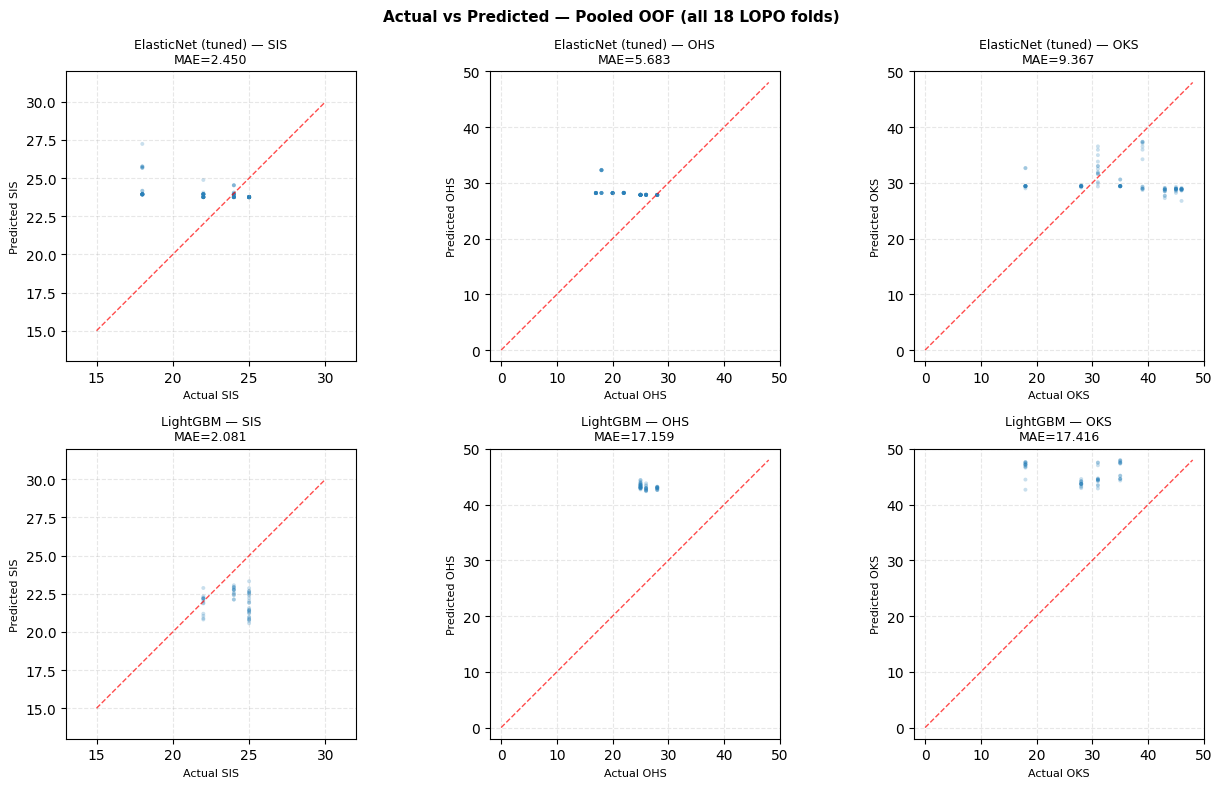

[OK] Saved -> C:\Users\Alessio\HOME\Git Projects (local)\MAISON-ML\Development AG\outputs\run_v7\figures\oof_scatter_actual_vs_predicted.png


In [64]:
# Plot pooled out-of-fold predictions for ElasticNet and LightGBM

SCATTER_MODELS = {
    'tuned_elasticnet': 'ElasticNet (tuned)',
    'lgbm':             'LightGBM',
}
TARGET_RANGES = {
    TARGET_SIS: (15, 30, 'SIS'),
    TARGET_OHS: (0,  48, 'OHS'),
    TARGET_OKS: (0,  48, 'OKS'),
}

fig, axes = plt.subplots(len(SCATTER_MODELS), len(TARGET_RANGES),
                          figsize=(13, 8))
fig.suptitle('Actual vs Predicted — Pooled OOF (all 18 LOPO folds)',
             fontsize=11, fontweight='bold')

for row_i, (m_tag, m_label) in enumerate(SCATTER_MODELS.items()):
    for col_i, (target, (tmin, tmax, tlabel)) in enumerate(TARGET_RANGES.items()):
        ax = axes[row_i][col_i]
        key = f'{m_tag}_{target}'
        if key not in oof_pred_store or not oof_pred_store[key]['y_true']:
            ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                    transform=ax.transAxes)
            continue
        y_true = np.array(oof_pred_store[key]['y_true'])
        y_pred_oof = np.array(oof_pred_store[key]['y_pred'])
        ax.scatter(y_true, y_pred_oof, alpha=0.25, s=8,
                   color='#2980b9', edgecolors='none')
        diag = np.linspace(tmin, tmax, 100)
        ax.plot(diag, diag, 'r--', linewidth=1, alpha=0.7, label='perfect')
        mae_all = np.mean(np.abs(y_true - y_pred_oof))
        ax.set_xlabel(f'Actual {tlabel}', fontsize=8)
        ax.set_ylabel(f'Predicted {tlabel}', fontsize=8)
        ax.set_title(f'{m_label} — {tlabel}\nMAE={mae_all:.3f}', fontsize=9)
        ax.set_xlim(tmin - 2, tmax + 2)
        ax.set_ylim(tmin - 2, tmax + 2)
        ax.set_aspect('equal', 'box')
        ax.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
scatter_path = FIGURES_DIR / 'oof_scatter_actual_vs_predicted.png'
plt.savefig(scatter_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close('all')
print(f'[OK] Saved -> {scatter_path}')

In [65]:
oof_pred_store

{'tuned_ridge_sis': {'y_true': [25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   25,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   24,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   22,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18,
   18],
  'y_pred': [18.007759929607992,
   27.617582461693367,
   21.163642004773717,
   22.328516135001596,
   22.705261058010876,
   23.49911636567009,
   21.41258429288356,
   22.61668288654

# Build delta targets using each participant's earliest clinical block as baseline

In [66]:

_raw_clin = df[[PARTICIPANT_COL, DATE_COL, CLINICAL_TS_COL]].copy()
_raw_clin[CLINICAL_TS_COL] = pd.to_datetime(_raw_clin[CLINICAL_TS_COL])

# Add clinical timestamp back so the earliest block can be identified
_df_clin = (
    df_model[[PARTICIPANT_COL, DATE_COL, TARGET_SIS, TARGET_OHS, TARGET_OKS]]
    .merge(_raw_clin, on=[PARTICIPANT_COL, DATE_COL], how='left')
)

# Take the first clinical block for each participant
_baselines = (
    _df_clin
    .sort_values([PARTICIPANT_COL, CLINICAL_TS_COL])
    .groupby(PARTICIPANT_COL, sort=False)[[TARGET_SIS, TARGET_OHS, TARGET_OKS]]
    .first()
    .rename(columns={TARGET_SIS: 'baseline_sis', TARGET_OHS: 'baseline_ohs',
                     TARGET_OKS: 'baseline_oks'})
    .reset_index()
)

print("Participant baselines (SIS / OHS / OKS at earliest clinical block):")
print(_baselines.to_string(index=False))

TARGET_SIS_DELTA = 'sis_delta'
TARGET_OHS_DELTA = 'ohs_delta'
TARGET_OKS_DELTA = 'oks_delta'

df_model_delta = (
    df_model.copy()
    .merge(_baselines, on=PARTICIPANT_COL, how='left')
)
df_model_delta[TARGET_SIS_DELTA] = (
    df_model_delta[TARGET_SIS] - df_model_delta['baseline_sis']
).astype(float)
df_model_delta[TARGET_OHS_DELTA] = (
    df_model_delta[TARGET_OHS] - df_model_delta['baseline_ohs']
).astype(float)
df_model_delta[TARGET_OKS_DELTA] = (
    df_model_delta[TARGET_OKS] - df_model_delta['baseline_oks']
).astype(float)
df_model_delta = df_model_delta.drop(columns=['baseline_sis', 'baseline_ohs', 'baseline_oks'])

print()
for _dtgt in [TARGET_SIS_DELTA, TARGET_OHS_DELTA, TARGET_OKS_DELTA]:
    _rng = df_model_delta[_dtgt]
    print(f"  {_dtgt}: min={_rng.min():.1f}  max={_rng.max():.1f}  "
          f"mean={_rng.mean():.2f}  std={_rng.std():.2f}  n_unique={_rng.nunique()}")

print(f"\n[OK] df_model_delta ready: {df_model_delta.shape}")

Participant baselines (SIS / OHS / OKS at earliest clinical block):
 participant  baseline_sis  baseline_ohs  baseline_oks
           1            25            25            31
           2            18            18            39
           3            26            28            48
           4            26            41            23
           5            28            36            44
           6            26            42            39
           7            24            35            31
           8            23            24            24
           9            25            19            21
          10            19            19            26
          11            15            47            48
          12            29            31            16
          13            22            28            39
          14            25            27            19
          15            17            28            19
          16            28            28            

# Run the same LOPO pipeline again, but with delta targets

In [69]:
DELTA_SPECS = [
    # (tag, model_class, model_kwargs, param_grid, selector)
    ('tuned_ridge',
     Ridge,
     dict(),
     PARAM_GRID_RIDGE,
     None),
    ('tuned_elasticnet',
     ElasticNet,
     dict(max_iter=10000, random_state=seed),
     PARAM_GRID_ELASTICNET,
     None),
    ('rf',
     RandomForestRegressor,
     dict(random_state=seed, n_jobs=1),
     PARAM_GRID_RF,
     None),
    ('lgbm',
     LGBMRegressor,
     dict(random_state=seed, verbosity=-1, n_jobs=1),
     PARAM_GRID_LGB,
     None),
]

logo_d    = LeaveOneGroupOut()
groups_d  = df_model_delta[PARTICIPANT_COL].values
n_folds_d = len(df_model_delta[PARTICIPANT_COL].unique())
MAX_FOLDS_D = n_folds_d

print("=== Delta-Target LOPO-CV ===")
print(f"  Folds    : {MAX_FOLDS_D}")
print(f"  Targets  : {TARGET_SIS_DELTA}, {TARGET_OHS_DELTA}, {TARGET_OKS_DELTA}")
print(f"  Models   : {[s[0] for s in DELTA_SPECS]}")
print()

delta_records = []

=== Delta-Target LOPO-CV ===
  Folds    : 18
  Targets  : sis_delta, ohs_delta, oks_delta
  Models   : ['tuned_ridge', 'tuned_elasticnet', 'rf', 'lgbm']



In [70]:
for fold_idx, (train_idx, test_idx) in enumerate(
        logo_d.split(df_model_delta, groups=groups_d)):

    if fold_idx >= MAX_FOLDS_D:
        break

    df_train_d = df_model_delta.iloc[train_idx].copy()
    df_test_d  = df_model_delta.iloc[test_idx].copy()

    train_pids_d   = set(df_train_d[PARTICIPANT_COL].unique())
    test_pids_d    = set(df_test_d[PARTICIPANT_COL].unique())
    held_out_pid_d = int(list(test_pids_d)[0])

    assert len(train_pids_d & test_pids_d) == 0, \
        f"Fold {fold_idx+1}: participant overlap in delta loop"

    # Merge demographics inside the fold
    df_train_dm = df_train_d.merge(ana, on=PARTICIPANT_COL, how='left')
    df_test_dm  = df_test_d.merge(ana,  on=PARTICIPANT_COL, how='left')

    # Build rolling features separately for train and test
    df_tr_d_fe = make_features(df_train_dm, windows=WINDOWS)
    df_te_d_fe = make_features(df_test_dm,  windows=WINDOWS)

    n_inner_d   = min(len(train_pids_d), 5)
    inner_cv_d  = GroupKFold(n_splits=n_inner_d)
    inner_grp_d = df_tr_d_fe[PARTICIPANT_COL].values

    fold_rec_d = {
        'fold'         : fold_idx + 1,
        'held_out_pid' : held_out_pid_d,
    }

    print(f"  Fold {fold_idx+1:02d}/{MAX_FOLDS_D} | held-out P{held_out_pid_d:02d}")

    # Naive mean baseline for delta targets  (sarebbe quello che chiamavo Baseline B)
    for dtgt in [TARGET_SIS_DELTA, TARGET_OHS_DELTA, TARGET_OKS_DELTA]:
        train_delta_mean = float(df_train_dm[dtgt].mean())
        y_te_d_vals = df_test_dm[dtgt].values
        y_pred_d_bl = np.full(len(y_te_d_vals), train_delta_mean)
        mae_d_bl = mean_absolute_error(y_te_d_vals, y_pred_d_bl)
        r2_d_bl  = r2_score(y_te_d_vals, y_pred_d_bl)
        fold_rec_d[f'naive_mean_mae_{dtgt}'] = round(mae_d_bl, 4)
        fold_rec_d[f'naive_mean_r2_{dtgt}']  = round(r2_d_bl,  4)
        print(f"    -> [{dtgt}] naive_mean          "
              f"MAE={mae_d_bl:.3f}  R2={r2_d_bl:.3f}")

    for model_tag, model_cls, model_kwargs, param_grid, selector in DELTA_SPECS:
        for dtgt in [TARGET_SIS_DELTA, TARGET_OHS_DELTA, TARGET_OKS_DELTA]:
            estimator = model_cls(**model_kwargs)
            pipe = build_model_pipeline(estimator, num_cols=ALL_NUM_COLS)
            search = GridSearchCV(
                pipe, 
                param_grid,
                cv=inner_cv_d,
                scoring='neg_mean_absolute_error',
                refit=True, 
                n_jobs=-1,
            )
            search.fit(
                df_tr_d_fe[FEAT_COLS_ROLLED],
                df_tr_d_fe[dtgt],
                groups=inner_grp_d,
            )
            y_pred_d = search.predict(df_te_d_fe[FEAT_COLS_ROLLED])

            mae_d = mean_absolute_error(df_te_d_fe[dtgt], y_pred_d)
            r2_d  = r2_score(df_te_d_fe[dtgt], y_pred_d)
            fold_rec_d[f'{model_tag}_mae_{dtgt}']  = round(mae_d, 4)
            fold_rec_d[f'{model_tag}_r2_{dtgt}']   = round(r2_d,  4)
            print(f"    -> [{dtgt}] {model_tag:<18}  "
                  f"MAE={mae_d:.3f}  R2={r2_d:.3f}")

    delta_records.append(fold_rec_d)

print()
print(f"[OK] {len(delta_records)}/{MAX_FOLDS_D} delta folds completed")

  Fold 01/18 | held-out P01
    -> [sis_delta] naive_mean          MAE=1.265  R2=-1.066
    -> [ohs_delta] naive_mean          MAE=2.294  R2=-3.509
    -> [oks_delta] naive_mean          MAE=5.000  R2=-0.185
    -> [sis_delta] tuned_ridge         MAE=1.743  R2=-1.772
    -> [ohs_delta] tuned_ridge         MAE=3.684  R2=-11.578
    -> [oks_delta] tuned_ridge         MAE=6.628  R2=-0.908
    -> [sis_delta] tuned_elasticnet    MAE=1.270  R2=-1.089
    -> [ohs_delta] tuned_elasticnet    MAE=2.390  R2=-3.809
    -> [oks_delta] tuned_elasticnet    MAE=5.002  R2=-0.175
    -> [sis_delta] rf                  MAE=1.515  R2=-1.902
    -> [ohs_delta] rf                  MAE=1.639  R2=-1.441
    -> [oks_delta] rf                  MAE=5.375  R2=-0.372
    -> [sis_delta] lgbm                MAE=2.045  R2=-3.690
    -> [ohs_delta] lgbm                MAE=1.715  R2=-1.687
    -> [oks_delta] lgbm                MAE=5.700  R2=-0.449
  Fold 02/18 | held-out P02
    -> [sis_delta] naive_mean          MAE=

KeyboardInterrupt: 

In [71]:
delta_records

[{'fold': 1,
  'held_out_pid': 1,
  'naive_mean_mae_sis_delta': 1.2647,
  'naive_mean_r2_sis_delta': -1.0663,
  'naive_mean_mae_ohs_delta': 2.2941,
  'naive_mean_r2_ohs_delta': -3.5087,
  'naive_mean_mae_oks_delta': 5.0,
  'naive_mean_r2_oks_delta': -0.1854,
  'tuned_ridge_mae_sis_delta': 1.7433,
  'tuned_ridge_r2_sis_delta': -1.7721,
  'tuned_ridge_mae_ohs_delta': 3.6842,
  'tuned_ridge_r2_ohs_delta': -11.5778,
  'tuned_ridge_mae_oks_delta': 6.628,
  'tuned_ridge_r2_oks_delta': -0.9083,
  'tuned_elasticnet_mae_sis_delta': 1.2701,
  'tuned_elasticnet_r2_sis_delta': -1.0895,
  'tuned_elasticnet_mae_ohs_delta': 2.3901,
  'tuned_elasticnet_r2_ohs_delta': -3.8093,
  'tuned_elasticnet_mae_oks_delta': 5.0021,
  'tuned_elasticnet_r2_oks_delta': -0.175,
  'rf_mae_sis_delta': 1.5149,
  'rf_r2_sis_delta': -1.9022,
  'rf_mae_ohs_delta': 1.6392,
  'rf_r2_ohs_delta': -1.4411,
  'rf_mae_oks_delta': 5.3746,
  'rf_r2_oks_delta': -0.3722,
  'lgbm_mae_sis_delta': 2.0446,
  'lgbm_r2_sis_delta': -3.6896,


# Save delta-target results and figures

In [72]:
DELTA_MODEL_MAP = {
    'baseline_naive_mean' : 'naive_mean_',
    'tuned_ridge'         : 'tuned_ridge_',
    'tuned_elasticnet'    : 'tuned_elasticnet_',
    'rf'                  : 'rf_',
    'lgbm'                : 'lgbm_',
}

delta_metric_rows = []
for rec in delta_records:
    for model_name, prefix in DELTA_MODEL_MAP.items():
        for dtgt in [TARGET_SIS_DELTA, TARGET_OHS_DELTA, TARGET_OKS_DELTA]:
            mae_key = f'{prefix}mae_{dtgt}'
            r2_key  = f'{prefix}r2_{dtgt}'
            if mae_key not in rec:
                continue
            delta_metric_rows.append({
                'model'        : model_name,
                'target'       : dtgt,
                'fold'         : rec['fold'],
                'held_out_pid' : rec['held_out_pid'],
                'mae'          : rec[mae_key],
                'r2'           : rec[r2_key],
            })

df_delta_metrics = pd.DataFrame(delta_metric_rows)

# Save per-fold results
delta_per_path = TABLES_DIR / 'lopo_metrics_per_participant_delta.csv'
df_delta_metrics.to_csv(delta_per_path, index=False)

# Save summary across folds
delta_summary = (
    df_delta_metrics
    .groupby(['model', 'target'])[['mae', 'r2']]
    .agg(['mean', 'std'])
    .round(4)
)
delta_summary.columns = ['mae_mean', 'mae_std', 'r2_mean', 'r2_std']
delta_summary = delta_summary.reset_index()
delta_sum_path = TABLES_DIR / 'lopo_metrics_summary_delta.csv'
delta_summary.to_csv(delta_sum_path, index=False)

# Print summary
print("=== Delta-Target Results (mean +/- std across LOPO folds) ===")
for dtgt in [TARGET_SIS_DELTA, TARGET_OHS_DELTA, TARGET_OKS_DELTA]:
    print(f"\n  Target: {dtgt.upper()}")
    _sub = delta_summary[delta_summary['target'] == dtgt].copy()
    _sub['MAE'] = _sub.apply(
        lambda r: f"{r['mae_mean']:.3f} +/- {r['mae_std']:.3f}", axis=1)
    _sub['R2']  = _sub.apply(
        lambda r: f"{r['r2_mean']:.3f} +/- {r['r2_std']:.3f}", axis=1)
    print(_sub[['model', 'MAE', 'R2']].to_string(index=False))

# Delta comparison figures
DELTA_MODEL_ORDER  = ['tuned_ridge', 'tuned_elasticnet', 'rf', 'lgbm']
DELTA_MODEL_LABELS = {
    'tuned_ridge'      : 'Ridge\n(tuned)',
    'tuned_elasticnet' : 'Elastic\nNet',
    'rf'               : 'Random\nForest',
    'lgbm'             : 'LightGBM',
}
DELTA_PALETTE = ['#2980b9', '#16a085', '#27ae60', '#e67e22']


def _make_delta_fig(dtgt, out_path):
    _sub = (
        delta_summary[delta_summary['target'] == dtgt]
        .set_index('model')
        .reindex(DELTA_MODEL_ORDER)
        .dropna(subset=['mae_mean'])
        .reset_index()
    )
    labels = [DELTA_MODEL_LABELS[m] for m in _sub['model']]
    colors = [DELTA_PALETTE[DELTA_MODEL_ORDER.index(m)] for m in _sub['model']]
    x = np.arange(len(_sub))
    n_folds_run_d = df_delta_metrics['fold'].nunique()

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    fig.suptitle(
        f'Delta-Target Comparison -- {dtgt.upper()}  '
        f'(LOPO-CV, {n_folds_run_d} folds)',
        fontsize=11, fontweight='bold',
    )
    metrics_spec = [
        (axes[0], 'mae_mean', 'mae_std', 'Mean Absolute Error', 'MAE (lower is better)'),
        (axes[1], 'r2_mean',  'r2_std',  'R2 Score',            'R2 (higher is better)'),
    ]
    for ax, metric, metric_std, title, ylabel in metrics_spec:
        std_vals = _sub[metric_std].fillna(0)
        bars = ax.bar(
            x, _sub[metric], width=0.45,
            yerr=std_vals, capsize=4,
            color=colors, edgecolor='white', linewidth=0.5,
            error_kw=dict(ecolor='#555555', elinewidth=1.2, capthick=1.2),
        )
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=9)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.set_title(title, fontsize=10)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        ax.set_axisbelow(True)
        if metric == 'r2_mean':
            ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
        for bar, val, err in zip(bars, _sub[metric], std_vals):
            label_y = val + err + abs(val) * 0.03 + 0.01
            ax.text(
                bar.get_x() + bar.get_width() / 2, label_y,
                f'{val:.2f}', ha='center', va='bottom', fontsize=8,
            )
    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f'[OK] Saved -> {out_path}')


_make_delta_fig(TARGET_SIS_DELTA, FIGURES_DIR / 'model_comparison_sis_delta.png')
_make_delta_fig(TARGET_OHS_DELTA, FIGURES_DIR / 'model_comparison_ohs_delta.png')
_make_delta_fig(TARGET_OKS_DELTA, FIGURES_DIR / 'model_comparison_oks_delta.png')

# Check that the delta outputs were saved
for _p in [delta_per_path, delta_sum_path,
           FIGURES_DIR / 'model_comparison_sis_delta.png',
           FIGURES_DIR / 'model_comparison_ohs_delta.png',
           FIGURES_DIR / 'model_comparison_oks_delta.png']:
    assert _p.exists() and _p.stat().st_size > 0, f"Missing delta output: {_p}"
    print(f'[OK] {_p.name}: {_p.stat().st_size:,} bytes')

print()
print('[OK] All delta outputs saved.')

=== Delta-Target Results (mean +/- std across LOPO folds) ===

  Target: SIS_DELTA
              model           MAE             R2
baseline_naive_mean 1.265 +/- nan -1.066 +/- nan
               lgbm 2.045 +/- nan -3.690 +/- nan
                 rf 1.515 +/- nan -1.902 +/- nan
   tuned_elasticnet 1.270 +/- nan -1.089 +/- nan
        tuned_ridge 1.743 +/- nan -1.772 +/- nan

  Target: OHS_DELTA
              model           MAE              R2
baseline_naive_mean 2.294 +/- nan  -3.509 +/- nan
               lgbm 1.715 +/- nan  -1.687 +/- nan
                 rf 1.639 +/- nan  -1.441 +/- nan
   tuned_elasticnet 2.390 +/- nan  -3.809 +/- nan
        tuned_ridge 3.684 +/- nan -11.578 +/- nan

  Target: OKS_DELTA
              model           MAE             R2
baseline_naive_mean 5.000 +/- nan -0.185 +/- nan
               lgbm 5.699 +/- nan -0.449 +/- nan
                 rf 5.375 +/- nan -0.372 +/- nan
   tuned_elasticnet 5.002 +/- nan -0.175 +/- nan
        tuned_ridge 6.628 +/- nan -0

# Statistical analysis

In [74]:
# Statistical analysis: Friedman tests and Nemenyi post-hoc comparisons
# Uses existing fold-level LOPO-CV MAE results only. No model retraining.

from pathlib import Path
from scipy.stats import friedmanchisquare
import pandas as pd
import numpy as np
import itertools
import math

# ---------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------

OUTPUTS_DIR = Path("outputs/run_v7")
TABLES_DIR = OUTPUTS_DIR / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

ABS_PER_FOLD_PATH = TABLES_DIR / "lopo_metrics_per_participant.csv"
DELTA_PER_FOLD_PATH = TABLES_DIR / "lopo_metrics_per_participant_delta.csv"

if not ABS_PER_FOLD_PATH.exists():
    raise FileNotFoundError(f"Missing file: {ABS_PER_FOLD_PATH}")

if not DELTA_PER_FOLD_PATH.exists():
    raise FileNotFoundError(f"Missing file: {DELTA_PER_FOLD_PATH}")

df_abs_fold = pd.read_csv(ABS_PER_FOLD_PATH)
df_delta_fold = pd.read_csv(DELTA_PER_FOLD_PATH)

print("[OK] Loaded fold-level MAE files")
print(f"Absolute-score file: {ABS_PER_FOLD_PATH}")
print(f"Delta-target file: {DELTA_PER_FOLD_PATH}")
print()

[OK] Loaded fold-level MAE files
Absolute-score file: outputs\run_v7\tables\lopo_metrics_per_participant.csv
Delta-target file: outputs\run_v7\tables\lopo_metrics_per_participant_delta.csv



In [75]:
# ---------------------------------------------------------------------
# Labels
# ---------------------------------------------------------------------

MODEL_LABELS = {
    "baseline_naive_mean": "Naive Mean",
    "tuned_ridge": "Ridge (tuned)",
    "tuned_elasticnet": "ElasticNet",
    "rf": "Random Forest",
    "lgbm": "LightGBM",
}

ABS_TARGETS = {
    "sis": "SIS",
    "ohs": "OHS",
    "oks": "OKS",
}

DELTA_TARGETS = {
    "sis_delta": "SIS Delta",
    "ohs_delta": "OHS Delta",
    "oks_delta": "OKS Delta",
}

In [77]:
# Nemenyi critical values for alpha = 0.05 from Demsar (2006), Table 5.
# These are q_alpha values for the two-tailed Nemenyi test.
NEMENYI_Q_ALPHA_005 = {
    2: 1.960,
    3: 2.343,
    4: 2.569,
    5: 2.728,
    6: 2.850,
    7: 2.949,
    8: 3.031,
    9: 3.102,
    10: 3.164,
}

In [ ]:
def run_friedman_and_nemenyi(df_metrics, setting_name, target_labels, model_order):  ### TODO: RIVEDERE
    """
    Run Friedman tests and, when significant, Nemenyi post-hoc comparisons.

    Friedman test:
        Overall non-parametric test comparing model rankings across LOPO folds.

    Nemenyi post-hoc test:
        Applied only when Friedman p-value < 0.05.
        Two models are significantly different if their average rank difference
        is larger than the critical difference (CD).

    Lower MAE is better, so lower rank is better.
    """

    friedman_rows = []
    average_rank_rows = []
    nemenyi_rows = []

    for target, target_label in target_labels.items():
        sub = df_metrics[df_metrics["target"] == target].copy()

        pivot = sub.pivot_table(
            index="held_out_pid",
            columns="model",
            values="mae",
            aggfunc="mean",
        )

        available_models = [model for model in model_order if model in pivot.columns]
        complete = pivot[available_models].dropna()

        n_folds = len(complete)
        n_models = len(available_models)

        if n_folds < 2 or n_models < 3:
            print(f"[WARN] Not enough complete data for: {setting_name} / {target_label}")
            continue

        model_arrays = [complete[model].values for model in available_models]
        friedman_stat, friedman_p = friedmanchisquare(*model_arrays)  ### *model_arrays apre la lista e passa ogni array come argomento

        # Rank models within each fold.
        # Lower MAE = better model = lower rank.
        ranks = complete.rank(axis=1, method="average", ascending=True)
        average_ranks = ranks.mean().sort_values()

        q_alpha = NEMENYI_Q_ALPHA_005[n_models]
        cd = q_alpha * math.sqrt((n_models * (n_models + 1)) / (6 * n_folds))


        friedman_rows.append({
            "setting": setting_name,
            "target": target_label,
            "n_folds": n_folds,
            "n_models": n_models,
            "models_compared": ", ".join(MODEL_LABELS.get(m, m) for m in available_models),
            "friedman_chi2": friedman_stat,
            "friedman_p_value": friedman_p,
            "nemenyi_cd_0.05": cd,
        })

        for model, avg_rank in average_ranks.items():
            average_rank_rows.append({
                "setting": setting_name,
                "target": target_label,
                "model": MODEL_LABELS.get(model, model),
                "average_rank": avg_rank,
                "n_folds": n_folds,
                "n_models": n_models,
                "friedman_p_value": friedman_p,
                "nemenyi_cd_0.05": cd,
            })

         # Nemenyi post-hoc comparisons only after significant Friedman result.
        if friedman_p < 0.05:
            for model_a, model_b in itertools.combinations(average_ranks.index, 2):
                rank_a = average_ranks[model_a]
                rank_b = average_ranks[model_b]
                rank_diff = abs(rank_a - rank_b)
                significant = rank_diff > cd

                nemenyi_rows.append({
                    "setting": setting_name,
                    "target": target_label,
                    "model_1": MODEL_LABELS.get(model_a, model_a),
                    "rank_1": rank_a,
                    "model_2": MODEL_LABELS.get(model_b, model_b),
                    "rank_2": rank_b,
                    "rank_difference": rank_diff,
                    "critical_difference_0.05": cd,
                    "significant": significant,
                })
                
    return (
        pd.DataFrame(friedman_rows),
        pd.DataFrame(average_rank_rows),
        pd.DataFrame(nemenyi_rows),
            )


In [ ]:
# Use the same five models in both absolute-score and delta-target settings.
# This keeps the Friedman and Nemenyi comparisons consistent.
# k = 5, so q_alpha = 2.728 and CD ≈ 1.44 for N = 18 LOPO folds.

model_order = [
    "baseline_naive_mean",
    "tuned_ridge",
    "tuned_elasticnet",
    "rf",
    "lgbm",
]

abs_model_order = model_order
delta_model_order = model_order

abs_friedman, abs_ranks, abs_nemenyi = run_friedman_and_nemenyi(   ### TODO: RIVEDERE
    df_metrics=df_abs_fold,
    setting_name="absolute_score",
    target_labels=ABS_TARGETS,
    model_order=abs_model_order,
)

delta_friedman, delta_ranks, delta_nemenyi = run_friedman_and_nemenyi(
    df_metrics=df_delta_fold,
    setting_name="delta_target",
    target_labels=DELTA_TARGETS,
    model_order=delta_model_order,
)

friedman_results = pd.concat([abs_friedman, delta_friedman], ignore_index=True)
average_rank_results = pd.concat([abs_ranks, delta_ranks], ignore_index=True)
nemenyi_results = pd.concat([abs_nemenyi, delta_nemenyi], ignore_index=True)

# Rounded display and saved outputs
friedman_display = friedman_results.copy()
friedman_display[["friedman_chi2", "friedman_p_value", "nemenyi_cd_0.05"]] = (
    friedman_display[["friedman_chi2", "friedman_p_value", "nemenyi_cd_0.05"]].round(4)
)

average_rank_display = average_rank_results.copy()
average_rank_display[["average_rank", "friedman_p_value", "nemenyi_cd_0.05"]] = (
    average_rank_display[["average_rank", "friedman_p_value", "nemenyi_cd_0.05"]].round(4)
)

nemenyi_display = nemenyi_results.copy()
if not nemenyi_display.empty:
    nemenyi_display[["rank_1", "rank_2", "rank_difference", "critical_difference_0.05"]] = (
        nemenyi_display[["rank_1", "rank_2", "rank_difference", "critical_difference_0.05"]].round(4)
    )

friedman_path = TABLES_DIR / "friedman_overall_tests.csv"
average_ranks_path = TABLES_DIR / "nemenyi_average_ranks.csv"
nemenyi_path = TABLES_DIR / "nemenyi_posthoc_pairs.csv"

friedman_display.to_csv(friedman_path, index=False)
average_rank_display.to_csv(average_ranks_path, index=False)
nemenyi_display.to_csv(nemenyi_path, index=False)


[WARN] Not enough complete data for: absolute_score / SIS
[WARN] Not enough complete data for: absolute_score / OHS
[WARN] Not enough complete data for: absolute_score / OKS
[WARN] Not enough complete data for: delta_target / SIS Delta
[WARN] Not enough complete data for: delta_target / OHS Delta
[WARN] Not enough complete data for: delta_target / OKS Delta


KeyError: "None of [Index(['friedman_chi2', 'friedman_p_value', 'nemenyi_cd_0.05'], dtype='object')] are in the [columns]"

In [80]:
print("=== Friedman overall tests ===")
print(friedman_display.to_string(index=False))
print()
print(f"[OK] Saved -> {friedman_path}")
print()

print("=== Average ranks for Nemenyi interpretation ===")
print(average_rank_display.to_string(index=False))
print()
print(f"[OK] Saved -> {average_ranks_path}")
print()

print("=== Nemenyi post-hoc pairwise comparisons ===")
if nemenyi_display.empty:
    print("No Nemenyi comparisons were run because no Friedman test was significant.")
else:
    print(nemenyi_display.to_string(index=False))
print()
print(f"[OK] Saved -> {nemenyi_path}")

=== Friedman overall tests ===
Empty DataFrame
Columns: []
Index: []



NameError: name 'friedman_path' is not defined

# Paper result plots

In [ ]:
# This version reads the saved CSV files, so it works after kernel restart.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TABLES_DIR = Path("outputs/run_v7/tables")
FIGURES_DIR = Path("outputs/run_v7/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

summary_path = TABLES_DIR / "lopo_metrics_summary.csv"
delta_summary_path = TABLES_DIR / "lopo_metrics_summary_delta.csv"

if not summary_path.exists():
    raise FileNotFoundError(f"Missing file: {summary_path}")

if not delta_summary_path.exists():
    raise FileNotFoundError(f"Missing file: {delta_summary_path}")

summary = pd.read_csv(summary_path)
delta_summary = pd.read_csv(delta_summary_path)

TARGET_ORDER_ABS = ["sis", "ohs", "oks"]
TARGET_ORDER_DELTA = ["sis_delta", "ohs_delta", "oks_delta"]

TARGET_LABELS = {
    "sis": "SIS",
    "ohs": "OHS",
    "oks": "OKS",
}

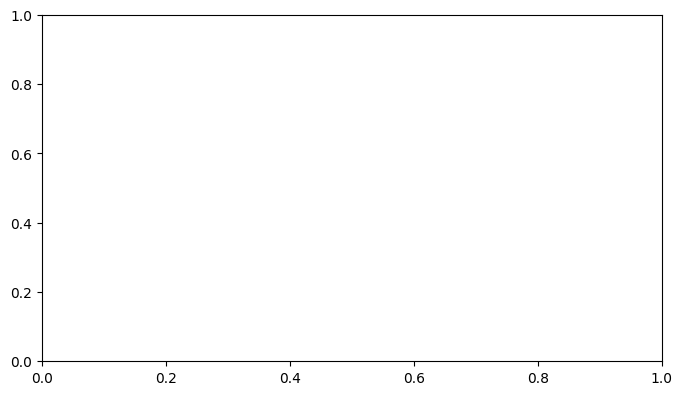

In [83]:
# ---------------------------------------------------
# Figure 1: Absolute-score MAE across main models
# ---------------------------------------------------
ABS_MODEL_ORDER = [
    "baseline_naive_mean",
    "tuned_elasticnet",
    "rf",
    "lgbm",
]

ABS_MODEL_LABELS = {
    "baseline_naive_mean": "Naive Mean",
    "tuned_elasticnet": "ElasticNet",
    "rf": "Random Forest",
    "lgbm": "LightGBM",
}

x = np.arange(len(TARGET_ORDER_ABS))
width = 0.18

fig, ax = plt.subplots(figsize=(8, 4.5))

In [89]:
summary

,model,target,mae_mean,mae_std,r2_mean,r2_std
0,baseline_demo_ridge,ohs,13.7505,NaN,-126.0499,NaN
1,baseline_demo_ridge,oks,11.4444,NaN,-3.3158,NaN
2,baseline_demo_ridge,sis,1.4943,NaN,-0.6516,NaN
3,baseline_naive_mean,ohs,2.2941,NaN,-3.5087,NaN
4,baseline_naive_mean,oks,5.0000,NaN,-0.1402,NaN
5,baseline_naive_mean,sis,1.0735,NaN,-0.0144,NaN
6,lgbm,ohs,17.1586,NaN,-196.7149,NaN
7,lgbm,oks,17.4161,NaN,-7.8492,NaN
8,lgbm,sis,2.0809,NaN,-3.1017,NaN
9,rf,ohs,15.9763,NaN,-170.6390,NaN


In [84]:
for i, model in enumerate(ABS_MODEL_ORDER):
    values = []
    errors = []

    for target in TARGET_ORDER_ABS:
        row = summary[
            (summary["model"] == model) &
            (summary["target"] == target)
        ]

        if row.empty:
            values.append(np.nan)
            errors.append(0)
        else:
            values.append(float(row["mae_mean"].iloc[0]))
            errors.append(float(row["mae_std"].iloc[0]))

    ax.bar(
        x + (i - 1.5) * width,
        values,
        width,
        yerr=errors,
        capsize=3,
        label=ABS_MODEL_LABELS[model],
    )


In [85]:
ax.set_xticks(x)
ax.set_xticklabels([TARGET_LABELS[t] for t in TARGET_ORDER_ABS])
ax.set_ylabel("MAE")
ax.set_xlabel("Clinical target")
ax.set_title("Absolute-score LOPO-CV MAE")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=2)

fig.tight_layout()

out_path = FIGURES_DIR / "absolute_mae_summary.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.close(fig)

print(f"[OK] Saved -> {out_path}")

[OK] Saved -> outputs\run_v7\figures\absolute_mae_summary.png


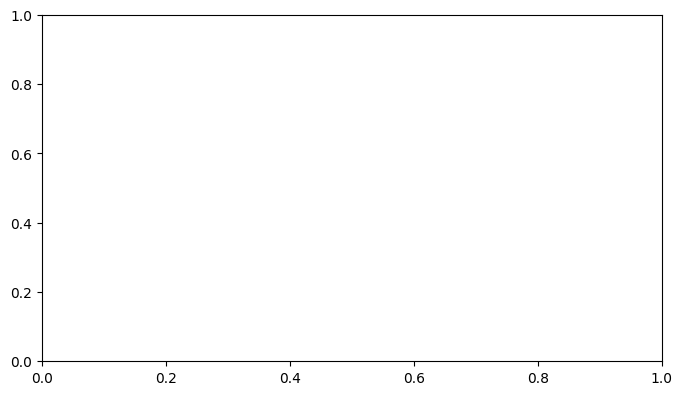

In [86]:
# ---------------------------------------------------
# Figure 2: Absolute-score vs delta-target MAE
# ---------------------------------------------------
COMPARE_SERIES = [
    ("baseline_naive_mean", "absolute", "Naive Mean Absolute"),
    ("baseline_naive_mean", "delta",    "Naive Mean Delta"),
    ("tuned_elasticnet",    "absolute", "ElasticNet Absolute"),
    ("tuned_elasticnet",    "delta",    "ElasticNet Delta"),
]

fig, ax = plt.subplots(figsize=(8, 4.5))

In [94]:
for i, (model, setting, label) in enumerate(COMPARE_SERIES):
    values = []
    errors = []
    print(model)

    for abs_target, delta_target in zip(TARGET_ORDER_ABS, TARGET_ORDER_DELTA):
        if setting == "absolute":
            src = summary
            target = abs_target
        else:
            src = delta_summary
            target = delta_target

        row = src[
            (src["model"] == model) &
            (src["target"] == target)
        ]

        if row.empty:
            values.append(np.nan)
            errors.append(0)
        else:
            values.append(float(row["mae_mean"].iloc[0]))
            errors.append(float(row["mae_std"].iloc[0]))

    ax.bar(
        x + (i - 1.5) * width,
        values,
        width,
        yerr=errors,
        capsize=3,
        label=label,
    )

baseline_naive_mean
baseline_naive_mean
tuned_elasticnet
tuned_elasticnet


In [95]:
COMPARE_SERIES

[('baseline_naive_mean', 'absolute', 'Naive Mean Absolute'),
 ('baseline_naive_mean', 'delta', 'Naive Mean Delta'),
 ('tuned_elasticnet', 'absolute', 'ElasticNet Absolute'),
 ('tuned_elasticnet', 'delta', 'ElasticNet Delta')]

In [88]:
ax.set_xticks(x)
ax.set_xticklabels([TARGET_LABELS[t] for t in TARGET_ORDER_ABS])
ax.set_ylabel("MAE")
ax.set_xlabel("Clinical target")
ax.set_title("Absolute-score vs delta-target MAE")
ax.grid(axis="y", alpha=0.3, linestyle="--")
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=2)

fig.tight_layout()

out_path = FIGURES_DIR / "absolute_vs_delta_mae.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.close(fig)

print(f"[OK] Saved -> {out_path}")

[OK] Saved -> outputs\run_v7\figures\absolute_vs_delta_mae.png


# Run a simple SHAP analysis on one representative fold

In [96]:
# Run a simple SHAP analysis on one representative fold

SHAP_PID = 1   # participant held out for the SHAP example

# Split the data for the SHAP fold
shap_mask_te  = df_model[PARTICIPANT_COL] == SHAP_PID
df_shap_tr    = df_model[~shap_mask_te].copy()
df_shap_te    = df_model[ shap_mask_te].copy()

df_shap_tr    = df_shap_tr.merge(ana, on=PARTICIPANT_COL, how='left')
df_shap_te    = df_shap_te.merge(ana, on=PARTICIPANT_COL, how='left')

df_shap_tr_fe = make_features(df_shap_tr, windows=WINDOWS)
df_shap_te_fe = make_features(df_shap_te, windows=WINDOWS)

print(f"SHAP fold: P{SHAP_PID} held out | "
      f"train={df_shap_tr_fe.shape[0]} rows | test={df_shap_te_fe.shape[0]} rows")

# Group features by modality for a simple SHAP summary
MODALITY_PREFIXES = {
    'acceleration': 'acceleration',
    'heartrate'   : 'heartrate',
    'motion'      : 'motion',
    'position'    : 'position',
    'sleep'       : 'sleep',
    'step'        : 'step',
    'demographics': ('age', 'sex', 'fracture', 'relationship', 'education',
                     'work', 'ethnicity'),
}

SHAP fold: P1 held out | train=952 rows | test=56 rows



SHAP Analysis: SIS
[OK] Saved -> outputs\run_v7\figures\shap_summary_sis.png

  Modality importance (sum of mean|SHAP|) -- SIS:
    acceleration  :  2.9118  ##############################
    step          :  2.0481  #####################
    sleep         :  1.4974  ###############
    motion        :  0.4998  #####
    heartrate     :  0.4795  ####
    demographics  :  0.3769  ###
    position      :  0.1416  #


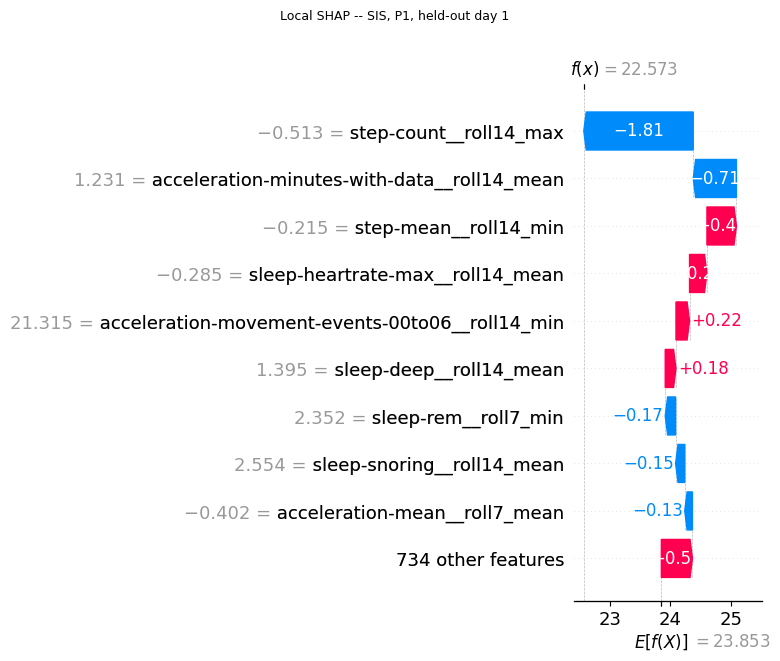

  [OK] Local explanation 1/3 shown inline


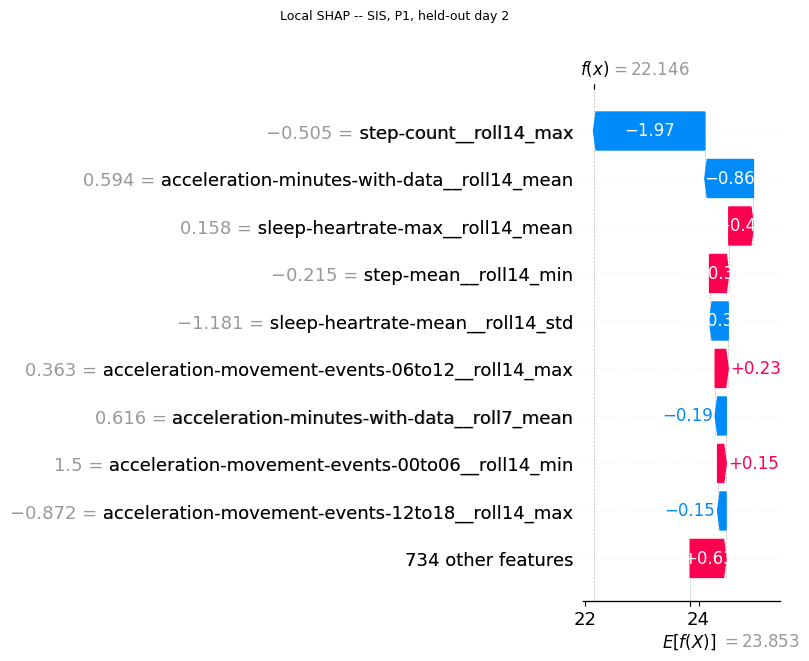

  [OK] Local explanation 2/3 shown inline


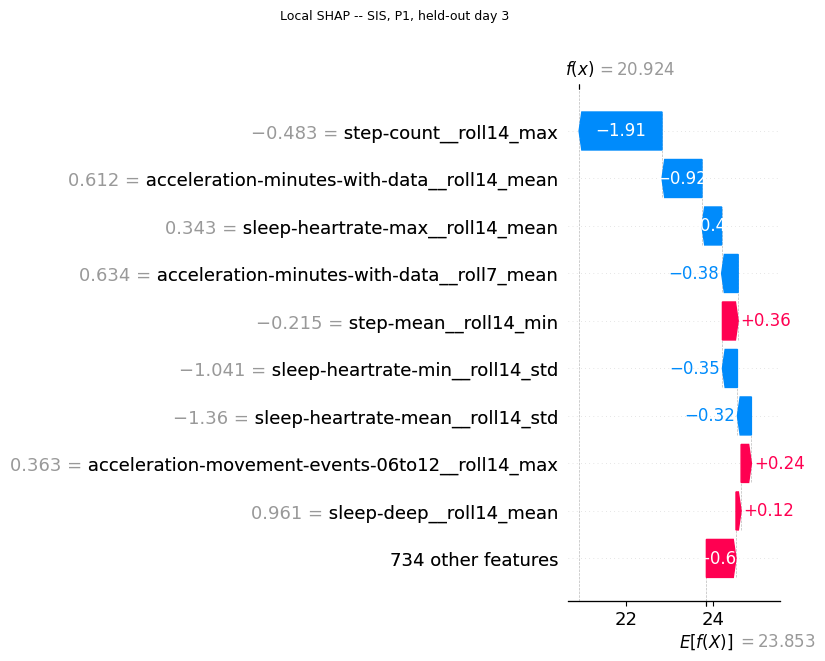

  [OK] Local explanation 3/3 shown inline

SHAP Analysis: OHS
[OK] Saved -> outputs\run_v7\figures\shap_summary_ohs.png

  Modality importance (sum of mean|SHAP|) -- OHS:
    sleep         :  7.9985  ##############################
    acceleration  :  3.3104  ############
    demographics  :  2.2453  ########
    motion        :  1.3609  #####
    heartrate     :  0.5307  #
    step          :  0.3171  #
    position      :  0.2251  #


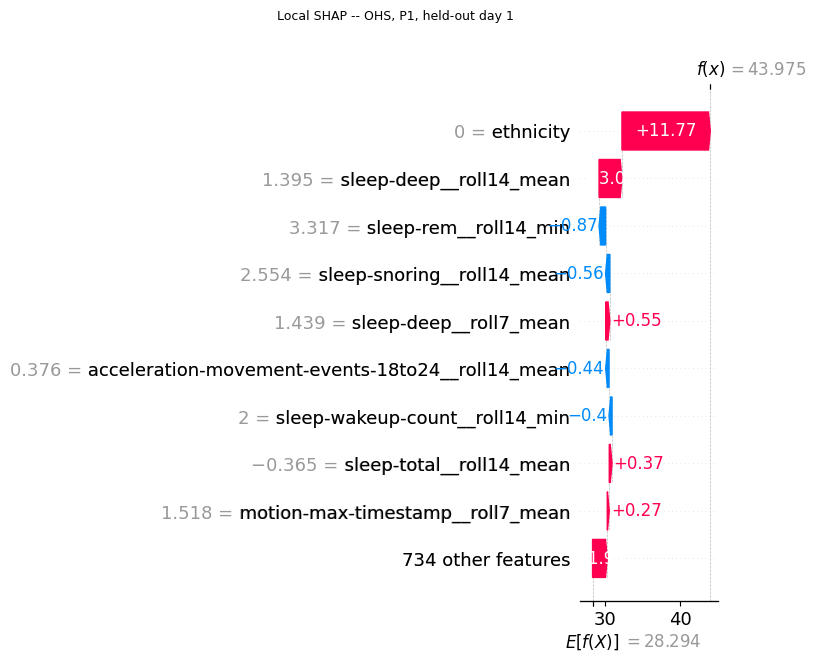

  [OK] Local explanation 1/3 shown inline


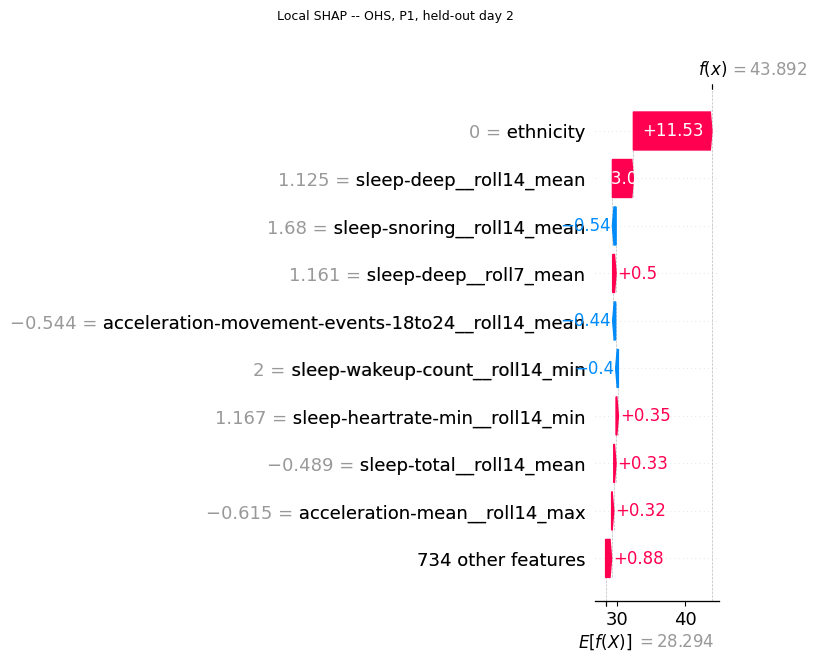

  [OK] Local explanation 2/3 shown inline


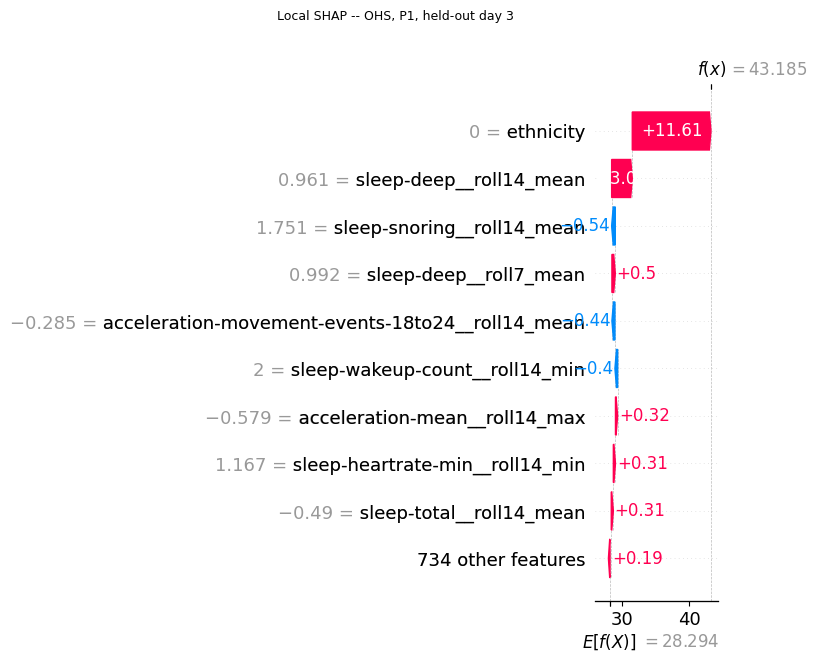

  [OK] Local explanation 3/3 shown inline

SHAP Analysis: OKS
[OK] Saved -> outputs\run_v7\figures\shap_summary_oks.png

  Modality importance (sum of mean|SHAP|) -- OKS:
    motion        :  9.3066  ##############################
    sleep         :  3.9072  ############
    acceleration  :  3.2822  ##########
    demographics  :  1.2548  ####
    heartrate     :  0.5915  #
    step          :  0.3790  #
    position      :  0.2263  #


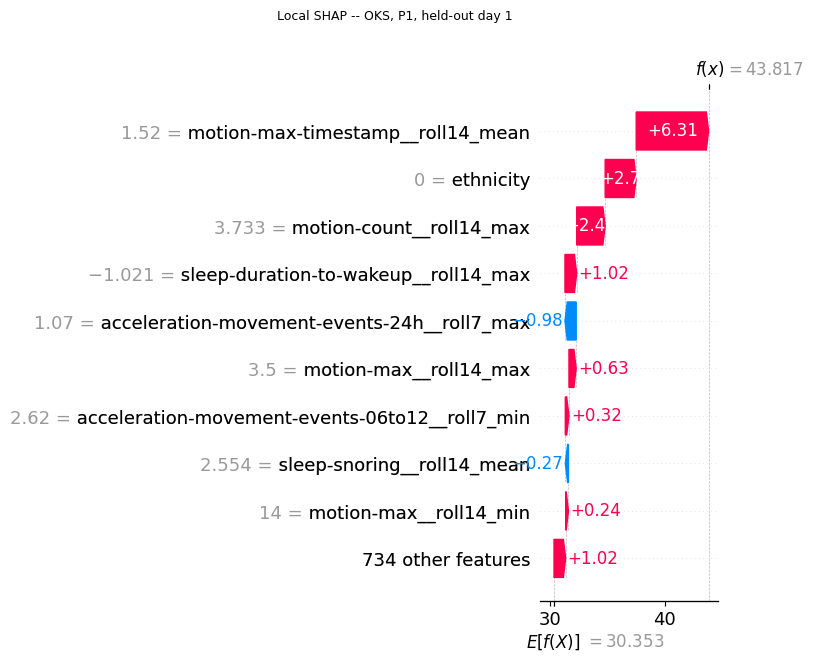

  [OK] Local explanation 1/3 shown inline


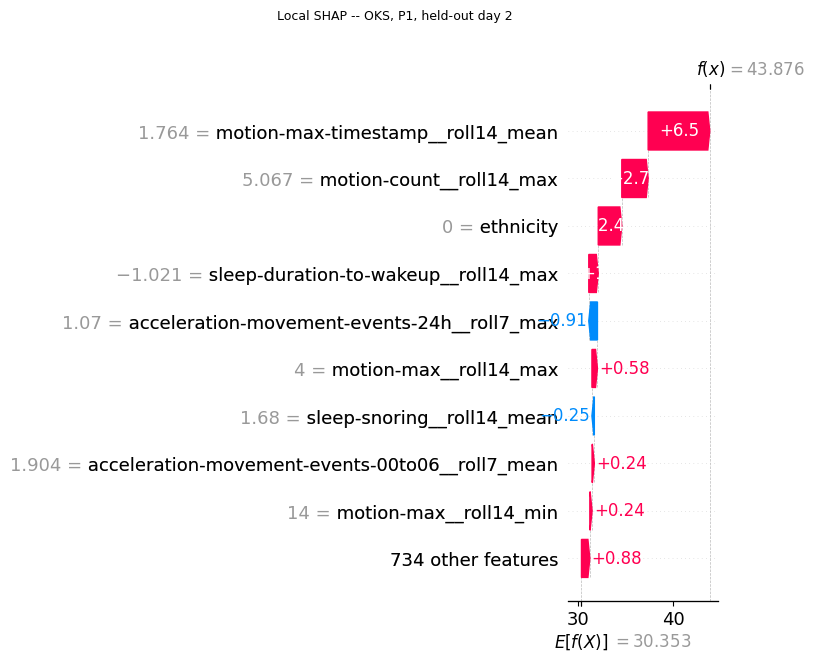

  [OK] Local explanation 2/3 shown inline


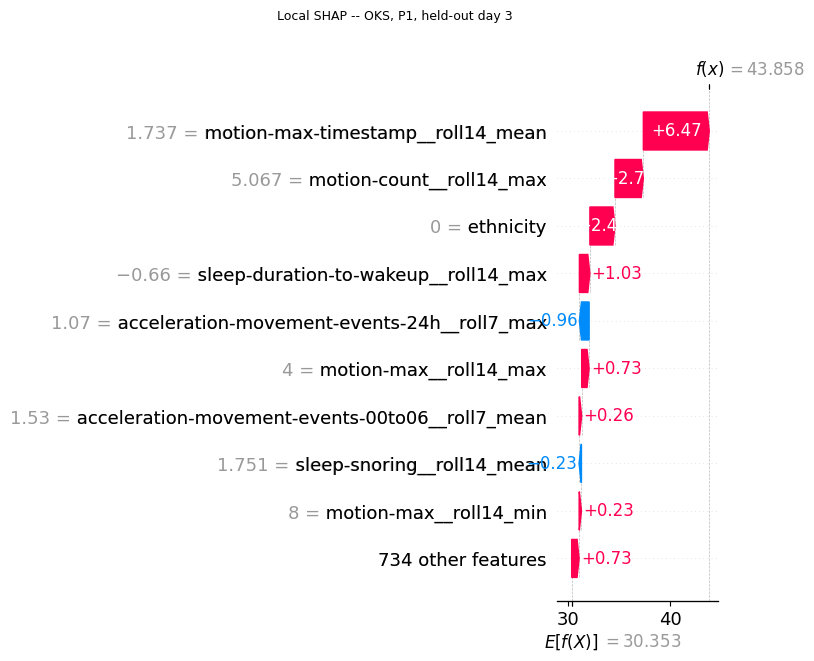

  [OK] Local explanation 3/3 shown inline


In [ ]:
for target in [TARGET_SIS, TARGET_OHS, TARGET_OKS]:
    print(f"\n{'='*60}")
    print(f"SHAP Analysis: {target.upper()}")
    print(f"{'='*60}")

    # Fit LightGBM on the SHAP training fold
    lgb_shap = LGBMRegressor(
        random_state=seed, verbosity=-1, n_jobs=1,
        n_estimators=100,   # keep this moderate so SHAP stays manageable
    )
    pipe_shap = build_model_pipeline(lgb_shap, num_cols=ALL_NUM_COLS)
    pipe_shap.fit(df_shap_tr_fe[FEAT_COLS_ROLLED], df_shap_tr_fe[target])

    # Get transformed arrays and cleaned feature names
    preproc   = pipe_shap.named_steps['preprocess']
    X_tr_arr  = preproc.transform(df_shap_tr_fe[FEAT_COLS_ROLLED])
    X_te_arr  = preproc.transform(df_shap_te_fe[FEAT_COLS_ROLLED])

    raw_names  = preproc.get_feature_names_out()
    feat_names = [n.replace('num__', '').replace('cat__', '') for n in raw_names]

    # Compute SHAP values
    lgb_fitted = pipe_shap.named_steps['model']
    explainer  = shap.TreeExplainer(lgb_fitted)    ### TODO: RIVEDERE
    shap_tr    = explainer.shap_values(X_tr_arr)
    shap_te    = explainer.shap_values(X_te_arr)

    # Global summary plot
    shap.summary_plot(
        shap_tr, X_tr_arr,
        feature_names=feat_names,
        max_display=20,
        show=False,
    )
    plt.gcf().set_size_inches(10, 7)
    plt.gcf().suptitle(
        f'SHAP Summary (Global) -- {target.upper()}   '
        f'[LightGBM, P{SHAP_PID} held out, top 20 of {len(feat_names)} features]',
        fontsize=10, fontweight='bold', y=1.02,
    )
    out_path = FIGURES_DIR / f'shap_summary_{target}.png'
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close()
    print(f'[OK] Saved -> {out_path}')

    # Modality-level importance   
    # si calcola la somma dei mean shap values per ciascuna "modalità" (es. accellerazione, ...)
    shap_abs_mean = np.abs(shap_tr).mean(axis=0)
    mod_importance = {}
    for mod, prefix in MODALITY_PREFIXES.items():
        if isinstance(prefix, tuple):
            idxs = [i for i, n in enumerate(feat_names)
                    if any(n.startswith(p) for p in prefix)]
        else:
            idxs = [i for i, n in enumerate(feat_names) if n.startswith(prefix)]
        mod_importance[mod] = float(shap_abs_mean[idxs].sum()) if idxs else 0.0

    print(f"\n  Modality importance (sum of mean|SHAP|) -- {target.upper()}:")
    max_val = max(mod_importance.values()) or 1.0
    for mod, val in sorted(mod_importance.items(), key=lambda kv: -kv[1]):
        bar = '#' * max(1, int(val / max_val * 30))
        print(f"    {mod:<14}: {val:7.4f}  {bar}")

    # Local examples for a few held-out days (waterfall plot)
    n_local = min(3, len(shap_te))
    for i in range(n_local):
        exp = shap.Explanation(              ### TODO: RIVEDERE
            values        = shap_te[i],
            base_values   = float(explainer.expected_value),
            data          = X_te_arr[i],
            feature_names = feat_names,
        )
        shap.plots.waterfall(exp, max_display=10, show=False)
        plt.gcf().suptitle(
            f'Local SHAP -- {target.upper()}, P{SHAP_PID}, held-out day {i+1}',
            fontsize=9, y=1.01,
        )
        plt.tight_layout()
        plt.show()
        plt.close('all')
        print(f'  [OK] Local explanation {i+1}/{n_local} shown inline')


# Final output check

In [98]:
# Final output check

from pathlib import Path

print("=" * 60)
print("FINAL OUTPUT GATE")
print("=" * 60)

REQUIRED_OUTPUTS = [
    (TABLES_DIR / "lopo_metrics_summary.csv", "Absolute-score summary table"),
    (TABLES_DIR / "lopo_metrics_summary_delta.csv", "Delta-target summary table"),
    (TABLES_DIR / "lopo_metrics_per_participant.csv", "Absolute-score per-participant results"),
    (TABLES_DIR / "lopo_metrics_per_participant_delta.csv", "Delta-target per-participant results"),
    (TABLES_DIR / "friedman_overall_tests.csv", "Friedman statistical tests"),
    (TABLES_DIR / "nemenyi_average_ranks.csv", "Nemenyi average ranks"),
    (TABLES_DIR / "nemenyi_posthoc_pairs.csv", "Nemenyi post-hoc pairwise comparisons"),
    (FIGURES_DIR / "absolute_vs_delta_mae.png", "Absolute-vs-delta MAE figure"),
]

SUPPLEMENTARY_OUTPUTS = [
    (TABLES_DIR / "baselines.csv", "Baseline results"),
    (FIGURES_DIR / "absolute_mae_summary.png", "Absolute-score MAE figure"),
]

def safe_relative_path(path):
    path = Path(path)
    try:
        return str(path.relative_to(ROOT)).replace("\\", "/")
    except ValueError:
        return str(path).replace("\\", "/")


all_ok = True

print("\nRequired outputs:")
for path, desc in REQUIRED_OUTPUTS:
    exists = path.exists()
    size = path.stat().st_size if exists else 0
    ok = exists and size > 0
    status = "[OK]" if ok else "[FAIL]"

    if not ok:
        all_ok = False

    rel = safe_relative_path(path)
    print(f"  {status} {desc}")
    print(f"       {rel} ({size:,} bytes)")

print("\nAdditional outputs (supplementary):")
for path, desc in SUPPLEMENTARY_OUTPUTS:
    exists = path.exists()
    size = path.stat().st_size if exists else 0
    status = "[OK]" if exists and size > 0 else "[MISS]"

    rel = safe_relative_path(path)
    print(f"  {status} {desc}")
    print(f"       {rel} ({size:,} bytes)")

print()

assert all_ok, (
    "One or more required outputs are missing or empty. "
    "Check the cells above for errors before uploading to GitHub."
)

print("[OK] All required outputs verified.")

FINAL OUTPUT GATE

Required outputs:
  [OK] Absolute-score summary table
       outputs/run_v7/tables/lopo_metrics_summary.csv (810 bytes)
  [OK] Delta-target summary table
       outputs/run_v7/tables/lopo_metrics_summary_delta.csv (633 bytes)
  [OK] Absolute-score per-participant results
       outputs/run_v7/tables/lopo_metrics_per_participant.csv (1,017 bytes)
  [OK] Delta-target per-participant results
       outputs/run_v7/tables/lopo_metrics_per_participant_delta.csv (656 bytes)
  [FAIL] Friedman statistical tests
       outputs/run_v7/tables/friedman_overall_tests.csv (0 bytes)
  [FAIL] Nemenyi average ranks
       outputs/run_v7/tables/nemenyi_average_ranks.csv (0 bytes)
  [FAIL] Nemenyi post-hoc pairwise comparisons
       outputs/run_v7/tables/nemenyi_posthoc_pairs.csv (0 bytes)
  [OK] Absolute-vs-delta MAE figure
       outputs/run_v7/figures/absolute_vs_delta_mae.png (73,238 bytes)

Additional outputs (supplementary):
  [OK] Baseline results
       outputs/run_v7/tables/ba

AssertionError: One or more required outputs are missing or empty. Check the cells above for errors before uploading to GitHub.